# 1. Setup
## 1.1 Setup n Setting Dependencies

In [1]:
!pip install -q emoji iterstrat
import os, sys, gc, time, math, copy, random, re, unicodedata, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedGroupKFold

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast, GradScaler

from transformers import AutoTokenizer, AutoModel, AutoConfig, get_cosine_schedule_with_warmup

# Pengecekan Akselerator GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch Version : {torch.__version__}")
print(f"CUDA Available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device Name     : {torch.cuda.get_device_name(0)}")
    print(f"Device Count    : {torch.cuda.device_count()}")



ERROR: Could not find a version that satisfies the requirement iterstrat (from versions: none)
ERROR: No matching distribution found for iterstrat
PyTorch Version : 2.11.0+cpu
CUDA Available  : False


## 1.2 Reproducibility & File Paths


In [4]:
import glob

def detect_data_paths():
    # 1. Cari rekursif di /kaggle/input (menangani ragam nama folder kompetisi di Kaggle)
    if os.path.exists('/kaggle/input'):
        matches = glob.glob('/kaggle/input/**/train.csv', recursive=True)
        if matches:
            train_p = os.path.abspath(matches[0])
            dir_p = os.path.dirname(train_p)
            test_p = os.path.join(dir_p, 'test.csv')
            return train_p, test_p, '/kaggle/working/'
            
    # 2. Kandidat path lokal
    candidates = ['.', '..', './dataset', '../dataset', './v8_outputs']
    for c in candidates:
        tp = os.path.join(c, 'train.csv')
        if os.path.exists(tp):
            return os.path.abspath(tp), os.path.abspath(os.path.join(c, 'test.csv')), './v8_outputs/'
            
    raise FileNotFoundError("train.csv dan test.csv tidak ditemukan di direktori manapun!")

TRAIN_PATH, TEST_PATH, OUTPUT_DIR = detect_data_paths()
print(f"TRAIN_PATH : {TRAIN_PATH}")
print(f"TEST_PATH  : {TEST_PATH}")
print(f"OUTPUT_DIR : {OUTPUT_DIR}")

class CFG:
    seed = 42
    n_folds = 5
    epochs = 3
    batch_size = 16
    lr = 2e-5
    min_lr = 1e-6
    weight_decay = 0.01
    warmup_ratio = 0.10
    max_grad_norm = 1.0
    fp16 = True
    
    # Backbone A: IndoBERTweet
    model_a_name = "indolem/indobertweet-base-uncased"
    max_len_a = 128
    weight_a = 0.55
    
    # Backbone B: IndoBERT-p2
    model_b_name = "indobenchmark/indobert-base-p2"
    max_len_b = 192
    weight_b = 0.45
    
    # Truncation Budget
    max_caption_tokens = 48
    
    output_dir = OUTPUT_DIR

os.makedirs(CFG.output_dir, exist_ok=True)

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(CFG.seed)
print(f"Environment: {'Kaggle' if os.path.exists('/kaggle/input') else 'Local'} | Seed: {CFG.seed}")



TRAIN_PATH : /kaggle/input/competitions/action-2026-data-mining-competition/train.csv
TEST_PATH  : /kaggle/input/competitions/action-2026-data-mining-competition/test.csv
OUTPUT_DIR : /kaggle/working/
Environment: Kaggle | Seed: 42


# 2. EDA
## 2.1 Data Ingestion & Pre-audit


In [5]:
# Load Dataset menggunakan path yang terdeteksi otomatis
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

target_cols = [
    'Infrastruktur', 'Kesehatan', 'Administrasi_Perizinan', 'Lingkungan_Kebersihan',
    'Ketertiban_Umum', 'Transportasi_LaluLintas', 'Sosial_Bantuan',
    'Keamanan_Kriminalitas', 'Pendidikan'
]

# Konversi target ke biner 0/1
for c in target_cols:
    train_df[c] = ((train_df[c].astype(str).str.lower().str.strip() == 'relevan') | (train_df[c] == 1)).astype(int)

print(f"Train Shape: {train_df.shape} | Test Shape: {test_df.shape}")
print("Distribusi Positif per Pilar:")
for c in target_cols:
    pos = train_df[c].sum()
    print(f"  {c:<25}: {pos:5d} ({pos/len(train_df)*100:5.2f}%)")



Train Shape: (23297, 14) | Test Shape: (34687, 5)
Distribusi Positif per Pilar:
  Infrastruktur            :  2803 (12.03%)
  Kesehatan                :  2574 (11.05%)
  Administrasi_Perizinan   :  1669 ( 7.16%)
  Lingkungan_Kebersihan    :  1993 ( 8.55%)
  Ketertiban_Umum          :  3191 (13.70%)
  Transportasi_LaluLintas  :  2226 ( 9.55%)
  Sosial_Bantuan           :  2885 (12.38%)
  Keamanan_Kriminalitas    :  2718 (11.67%)
  Pendidikan               :  2829 (12.14%)


## 2.2 Deklarasi Leksikon dan Pembersihan Beberapa Bagian


In [6]:
import emoji

# Peta substitusi Leetspeak (angka 2 dikecualikan karena penanda jamak warganet)
LEET_MAP = {"4": "a", "3": "e", "1": "i", "0": "o", "5": "s", "7": "t", "9": "g"}

# Regex pelindung entitas sah
PROTECT_PATTERN = re.compile(
    r"^(?:rt|rw|no|nomor|rp|jl|jln|gg|blok|uu)[.-]?\d+[a-z]?$"
    r"|^\d+(?:[.,]\d+)*(?:rb|ribu|jt|juta|k|km|kg|jam|th|tahun|x|an|%)?$"
    r"|^\d{1,2}[:.]\d{2}$"
    r"|^\d{4}$"
    r"|^\d+[a-zA-Z]$"
    r"|^\d+$",
    re.IGNORECASE
)

# Regex reduplikasi jamak orang tua (e.g. anak2 -> anak anak)
REDUP_PATTERN = re.compile(r"^([a-zA-Z]{3,})2$")

# Transliterasi Cyrillic homoglyph (anti-adversarial)
CYRILLIC_TO_LATIN = {
    'а': 'a', 'в': 'b', 'г': 'r', 'д': 'd', 'е': 'e',
    'з': 'z', 'і': 'i', 'ј': 'j', 'к': 'k', 'л': 'l',
    'м': 'm', 'н': 'h', 'о': 'o', 'р': 'p', 'с': 'c',
    'т': 't', 'у': 'y', 'х': 'x', 'ч': 'ch', 'ѕ': 's',
    'э': 'e', 'һ': 'h', 'ё': 'e', 'я': 'ya', 'ԁ': 'd',
    'ғ': 'f',
    'А': 'A', 'В': 'B', 'Г': 'R', 'Д': 'D', 'Е': 'E',
    'З': 'Z', 'І': 'I', 'Ј': 'J', 'К': 'K', 'Л': 'L',
    'М': 'M', 'Н': 'H', 'О': 'O', 'Р': 'P', 'С': 'C',
    'Т': 'T', 'У': 'Y', 'Х': 'X', 'Ч': 'Ch', 'Ѕ': 'S',
    'Э': 'E', 'Һ': 'H', 'Ё': 'E', 'Я': 'Ya', 'Ԁ': 'D',
    'Ғ': 'F'
}

# Kamus singkatan aduan publik & medsos
SLANG_DICT = {
    "yg": "yang", "dgn": "dengan", "utk": "untuk", "kpd": "kepada",
    "tdk": "tidak", "ga": "tidak", "gak": "tidak", "ngak": "tidak", "dak": "tidak",
    "blm": "belum", "sdh": "sudah", "udh": "sudah", "msh": "masih", "ttp": "tetap",
    "ank": "anak", "klau": "kalau", "bgt": "banget", "bgtt": "banget",
    "jd": "jadi", "jgn": "jangan", "sy": "saya",
    "pemda": "pemerintah daerah", "pemkot": "pemerintah kota", "pemprov": "pemerintah provinsi",
    "rsud": "rumah sakit umum daerah", "disdukcapil": "dinas kependudukan",
    "bpjs": "bpjs", "bansos": "bantuan sosial", "pkh": "pkh", "blt": "blt",
    "ktp": "ktp", "kk": "kk", "ptsl": "ptsl"
}

# Peta fallback emoji jika library emoji offline
EMOJI_FALLBACK = {
    "😡": " marah ", "🤬": " marah ", "😠": " marah ", "👿": " marah ",
    "😭": " sedih ", "😢": " sedih ", "🥺": " sedih ",
    "🤢": " jijik ", "🤮": " jijik ",
    "🚑": " ambulans ", "🏥": " rumah sakit ", "💉": " medis ", "😷": " sakit ",
    "🚧": " jalan rusak ", "🕳️": " lubang ", "🏗️": " proyek ", "💡": " lampu jalan ",
    "🌊": " banjir ", "🌧️": " hujan ", "🔥": " kebakaran ", "🗑️": " sampah ",
    "🚨": " darurat ", "👮": " polisi ", "🔪": " senjata ", "🥊": " tawuran ",
    "🙏": " mohon ", "👍": " bagus ", "👎": " buruk "
}

def clean_text_v8(text: str) -> str:
    if not isinstance(text, str) or not text.strip():
        return ""
    
    # 1. NFKC & Category Stripping (menghapus formatting kontrol, menyisakan teks utuh)
    text = unicodedata.normalize("NFKC", text)
    text = "".join(ch for ch in text if unicodedata.category(ch) not in ("Cf", "Cc", "Mn") or ch in "\n\t")
    
    # 2. Cyrillic Deobfuscation
    for cyr, lat in CYRILLIC_TO_LATIN.items():
        text = text.replace(cyr, lat)
        
    # 3. Token Alignment untuk Pretraining IndoBERTweet
    text = re.sub(r'https?://\S+|www\.\S+', 'HTTPURL', text)
    text = re.sub(r'@\w+', '@USER', text)
    
    # 4. Contextual Demojize (Spasi terbuka tanpa kurung siku)
    try:
        text = emoji.demojize(text, language="id", delimiters=(" ", " "))
        text = text.replace("_", " ")
    except Exception:
        for emo, txt in EMOJI_FALLBACK.items():
            text = text.replace(emo, txt)
        
    # 5. Token-Level Leetspeak & Slang Normalization
    tokens = text.split()
    cleaned_tokens = []
    for tok in tokens:
        if PROTECT_PATTERN.match(tok):
            cleaned_tokens.append(tok)
            continue
        m_redup = REDUP_PATTERN.match(tok)
        if m_redup:
            base = m_redup.group(1).lower()
            cleaned_tokens.append(f"{base} {base}")
            continue
        has_alpha = any(c.isalpha() for c in tok)
        has_leet = any(c in LEET_MAP for c in tok)
        if has_alpha and has_leet:
            cand = "".join(LEET_MAP.get(c, c) for c in tok.lower())
            tok = cand
        tok_lower = tok.lower()
        if tok_lower in SLANG_DICT:
            tok = SLANG_DICT[tok_lower]
        cleaned_tokens.append(tok)
        
    text = " ".join(cleaned_tokens)
    text = re.sub(r'[ 	]+', ' ', text)
    text = re.sub(r'\s*,\s*', ', ', text)
    text = re.sub(r'\s*\.\s*', '. ', text)
    text = re.sub(r',+', ',', text)
    text = re.sub(r'\.{2,}', '.', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

print("Menerapkan clean_text_v8 pada data...")
train_df['Judul_Clean'] = train_df['Judul_Caption'].fillna('').apply(clean_text_v8)
train_df['Teks_Clean'] = train_df['Teks'].fillna('').apply(clean_text_v8)
test_df['Judul_Clean'] = test_df['Judul_Caption'].fillna('').apply(clean_text_v8)
test_df['Teks_Clean'] = test_df['Teks'].fillna('').apply(clean_text_v8)
print("Sanitasi V8 Selesai 100%!")



Menerapkan clean_text_v8 pada data...
Sanitasi V8 Selesai 100%!


## 2.3 Setup EDA

In [7]:
# ===== EDA 0 | Setup, palet warna, helper =====
!pip install -q wordcloud emoji
import re, random, unicodedata, itertools, functools
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from wordcloud import WordCloud
import emoji

# 1. Satu palet untuk semua diagram
PAL  = {'dark': '#0B3C49', 'main': '#1F6F8B', 'mid': '#4FB0AE', 'light': '#99D5C9', 'pale': '#E8F4F2', 'accent': '#F2A541'}
CMAP = LinearSegmentedColormap.from_list('eda', [PAL['pale'], PAL['light'], PAL['mid'], PAL['main'], PAL['dark']])
def cat_colors(n): return [CMAP(0.35 + 0.65 * i / max(n - 1, 1)) for i in range(n)]

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.labelsize': 10, 'font.size': 10})

# 2. Konfigurasi kolom
TEXT_COL, CAP_COL, PLAT_COL = 'Teks', 'Judul_Caption', 'Source'
PILAR = target_cols
eda = train_df.copy()
eda[TEXT_COL] = eda[TEXT_COL].fillna('').astype(str)
PLATFORMS = sorted(eda[PLAT_COL].dropna().astype(str).unique())

# 3. Helper: bar horizontal berlabel
def barh(ax, s, title, total=None, color=None, fmt='{:,.0f}'):
    s = s.sort_values()
    ax.barh(s.index.astype(str), s.values, color=color or PAL['main'])
    for i, v in enumerate(s.values):
        ax.text(v, i, ' ' + fmt.format(v) + (f' ({v/total*100:.1f}%)' if total else ''), va='center', fontsize=9)
    ax.set_title(title); ax.margins(x=0.22); ax.grid(axis='x', alpha=.3); ax.set_axisbelow(True)

print(f'Train: {len(eda):,} | Platform: {PLATFORMS} | Pilar: {len(PILAR)}')

Train: 23,297 | Platform: ['Facebook', 'Instagram', 'TikTok', 'X (Twitter)', 'YouTube'] | Pilar: 9


## 2.4 Banyak Data Keseluruhan

Train: 23,297 | Test: 34,687 | Total: 57,984 | Caption unik (train): 105


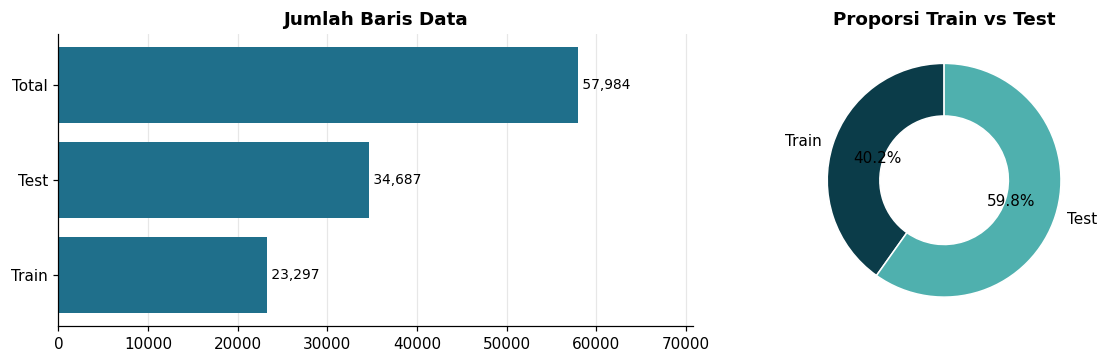

In [8]:
# ===== EDA 1 | Banyak data keseluruhan =====
n_tr, n_te = len(train_df), len(test_df)
n_cap = train_df[CAP_COL].nunique()
print(f'Train: {n_tr:,} | Test: {n_te:,} | Total: {n_tr+n_te:,} | Caption unik (train): {n_cap:,}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={'width_ratios': [1.3, 1]})
barh(ax[0], pd.Series({'Train': n_tr, 'Test': n_te, 'Total': n_tr + n_te}), 'Jumlah Baris Data', color=PAL['main'])
ax[1].pie([n_tr, n_te], labels=['Train', 'Test'], autopct='%1.1f%%', startangle=90, colors=[PAL['dark'], PAL['mid']],
          wedgeprops={'width': 0.45, 'edgecolor': 'white'}, textprops={'color': 'black'})
ax[1].set_title('Proporsi Train vs Test')
plt.tight_layout(); plt.show()

## 2.5 Banyak Data per Pilar

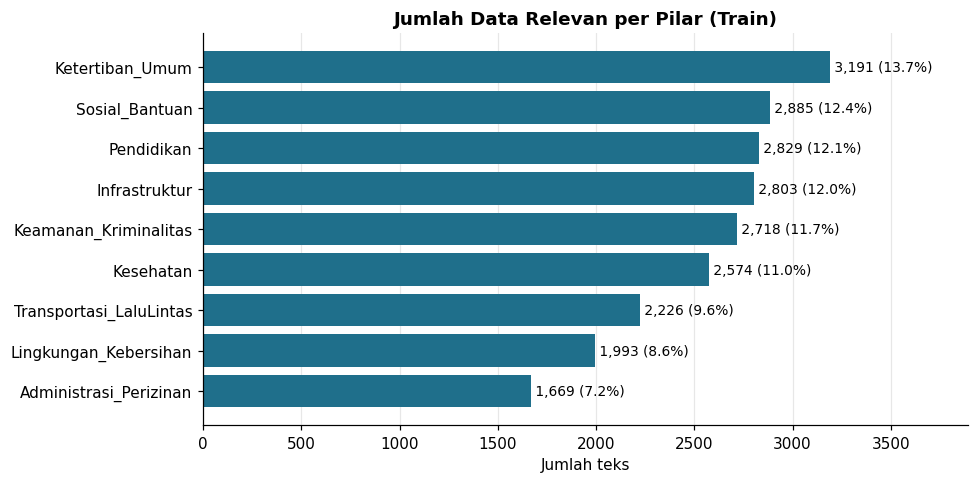

                         relevan  persen
Ketertiban_Umum             3191   13.70
Sosial_Bantuan              2885   12.38
Pendidikan                  2829   12.14
Infrastruktur               2803   12.03
Keamanan_Kriminalitas       2718   11.67
Kesehatan                   2574   11.05
Transportasi_LaluLintas     2226    9.55
Lingkungan_Kebersihan       1993    8.55
Administrasi_Perizinan      1669    7.16


In [9]:
# ===== EDA 2 | Banyak data tiap pilar (multi-label, relevan = 1) =====
pos = eda[PILAR].sum()
fig, ax = plt.subplots(figsize=(9, 4.5))
barh(ax, pos, 'Jumlah Data Relevan per Pilar (Train)', total=len(eda))
ax.set_xlabel('Jumlah teks')
plt.tight_layout(); plt.show()
print(pos.sort_values(ascending=False).to_frame('relevan').assign(persen=lambda d: (d.relevan / len(eda) * 100).round(2)))

## 2.6 Banyak Data tiap Platform

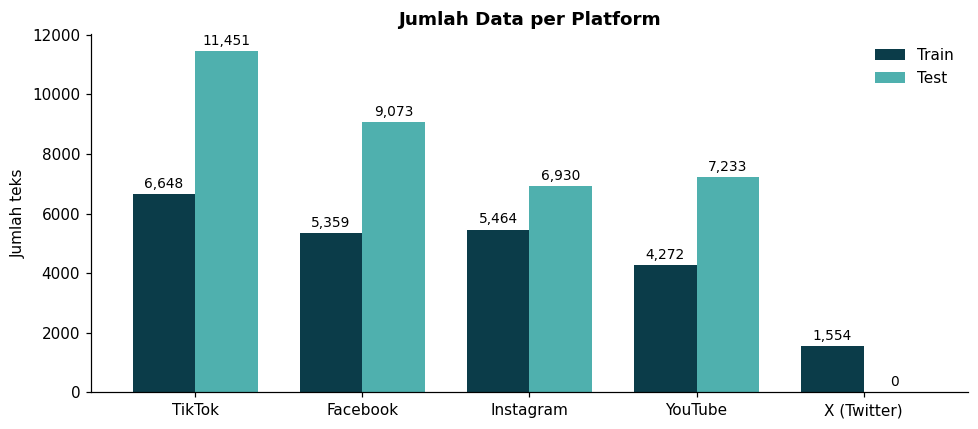

             Train   Test  persen_train
Source                                 
TikTok        6648  11451         28.54
Facebook      5359   9073         23.00
Instagram     5464   6930         23.45
YouTube       4272   7233         18.34
X (Twitter)   1554      0          6.67


In [10]:
# ===== EDA 3 | Banyak data tiap platform (Train vs Test) =====
plat = pd.DataFrame({'Train': train_df[PLAT_COL].value_counts(), 'Test': test_df[PLAT_COL].value_counts()}).fillna(0).astype(int)
plat = plat.loc[plat.sum(axis=1).sort_values(ascending=False).index]

ax = plat.plot(kind='bar', figsize=(9, 4), color=[PAL['dark'], PAL['mid']], width=.75, rot=0)
for c in ax.containers: ax.bar_label(c, fmt='{:,.0f}', fontsize=9, padding=2)
ax.set_title('Jumlah Data per Platform'); ax.set_xlabel(''); ax.set_ylabel('Jumlah teks'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print(plat.assign(persen_train=(plat.Train / plat.Train.sum() * 100).round(2)))

## 2.7 Tokenisasi untuk Wordcloud

In [11]:
# ===== EDA 4a | Tokenisasi mentah untuk word cloud (tanpa stopword removal / lemmatization / normalisasi slang) =====
URL_RE, MENT_RE, HASH_RE = re.compile(r'https?://\S+|www\.\S+'), re.compile(r'@\w+'), re.compile(r'#\w+')

def raw_tokens(text):
    t = unicodedata.normalize('NFKC', str(text)).lower()           # 1. NFKC + lowercase
    t = MENT_RE.sub(' ', URL_RE.sub(' ', t))                       # 2. buang URL & mention
    return [w for w in re.findall(r'[a-z0-9]+', t) if w.isalpha() and len(w) >= 2]   # 3. hanya kata alfabet (>=2 huruf)

eda['tokens'] = eda[TEXT_COL].map(raw_tokens)
ALL_FREQ = Counter(itertools.chain.from_iterable(eda['tokens']))
print(f'Total token: {sum(ALL_FREQ.values()):,} | Vocab unik: {len(ALL_FREQ):,}')

# 4. Helper word cloud (warna mengikuti palet)
CLOUD_COLORS = [PAL['dark'], PAL['main'], PAL['mid'], PAL['accent']]
def _color(word, font_size, position, orientation, random_state=None, **kw):
    return (random_state or random).choice(CLOUD_COLORS)

def cloud(ax, counter, title, max_words=70):
    ax.set_title(title, fontsize=11); ax.axis('off')
    if not counter: return
    wc = WordCloud(width=700, height=420, background_color='white', max_words=max_words, stopwords=set(),
                   color_func=_color, prefer_horizontal=0.9, random_state=42).generate_from_frequencies(counter)
    ax.imshow(wc, interpolation='bilinear')

def group_counter(mask): return Counter(itertools.chain.from_iterable(eda.loc[mask, 'tokens']))

Total token: 303,593 | Vocab unik: 42,941


## 2.8 Word Cloud Keseluruhan

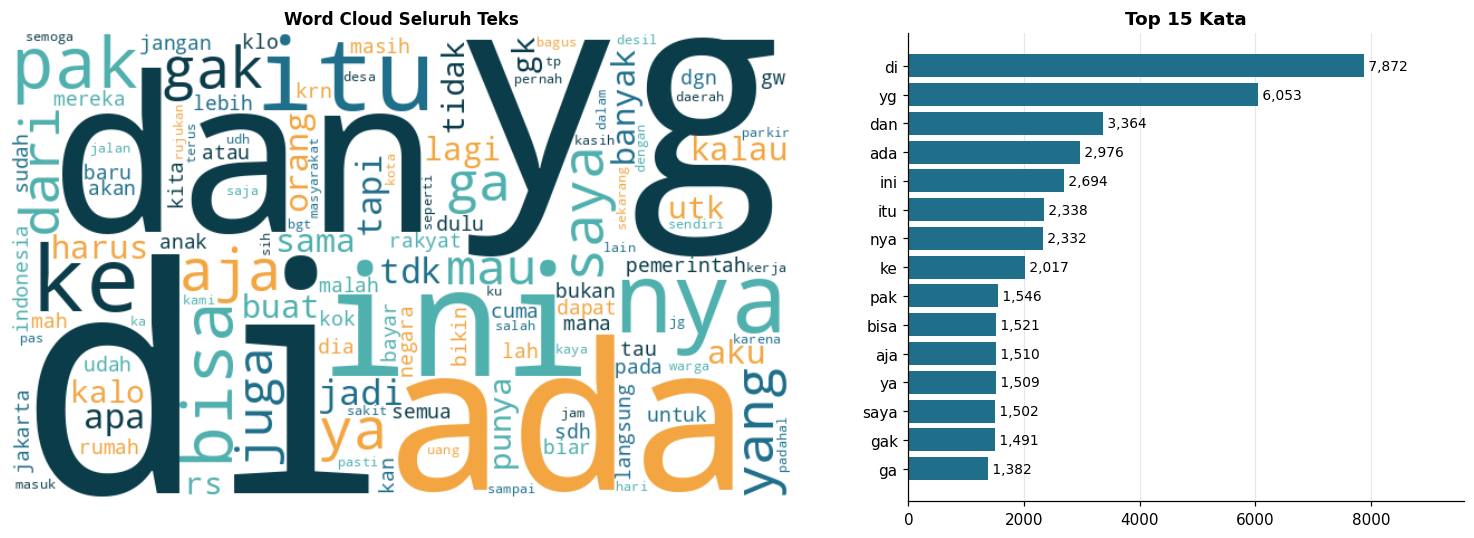

In [13]:
# ===== EDA 4 | Word cloud keseluruhan + Top 15 kata =====
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.6, 1]})
cloud(ax[0], ALL_FREQ, 'Word Cloud Seluruh Teks', max_words=120)
barh(ax[1], pd.Series(dict(ALL_FREQ.most_common(15))), 'Top 15 Kata')
plt.tight_layout(); plt.show()

## 2.9 Word Cloud Tiap Pilar

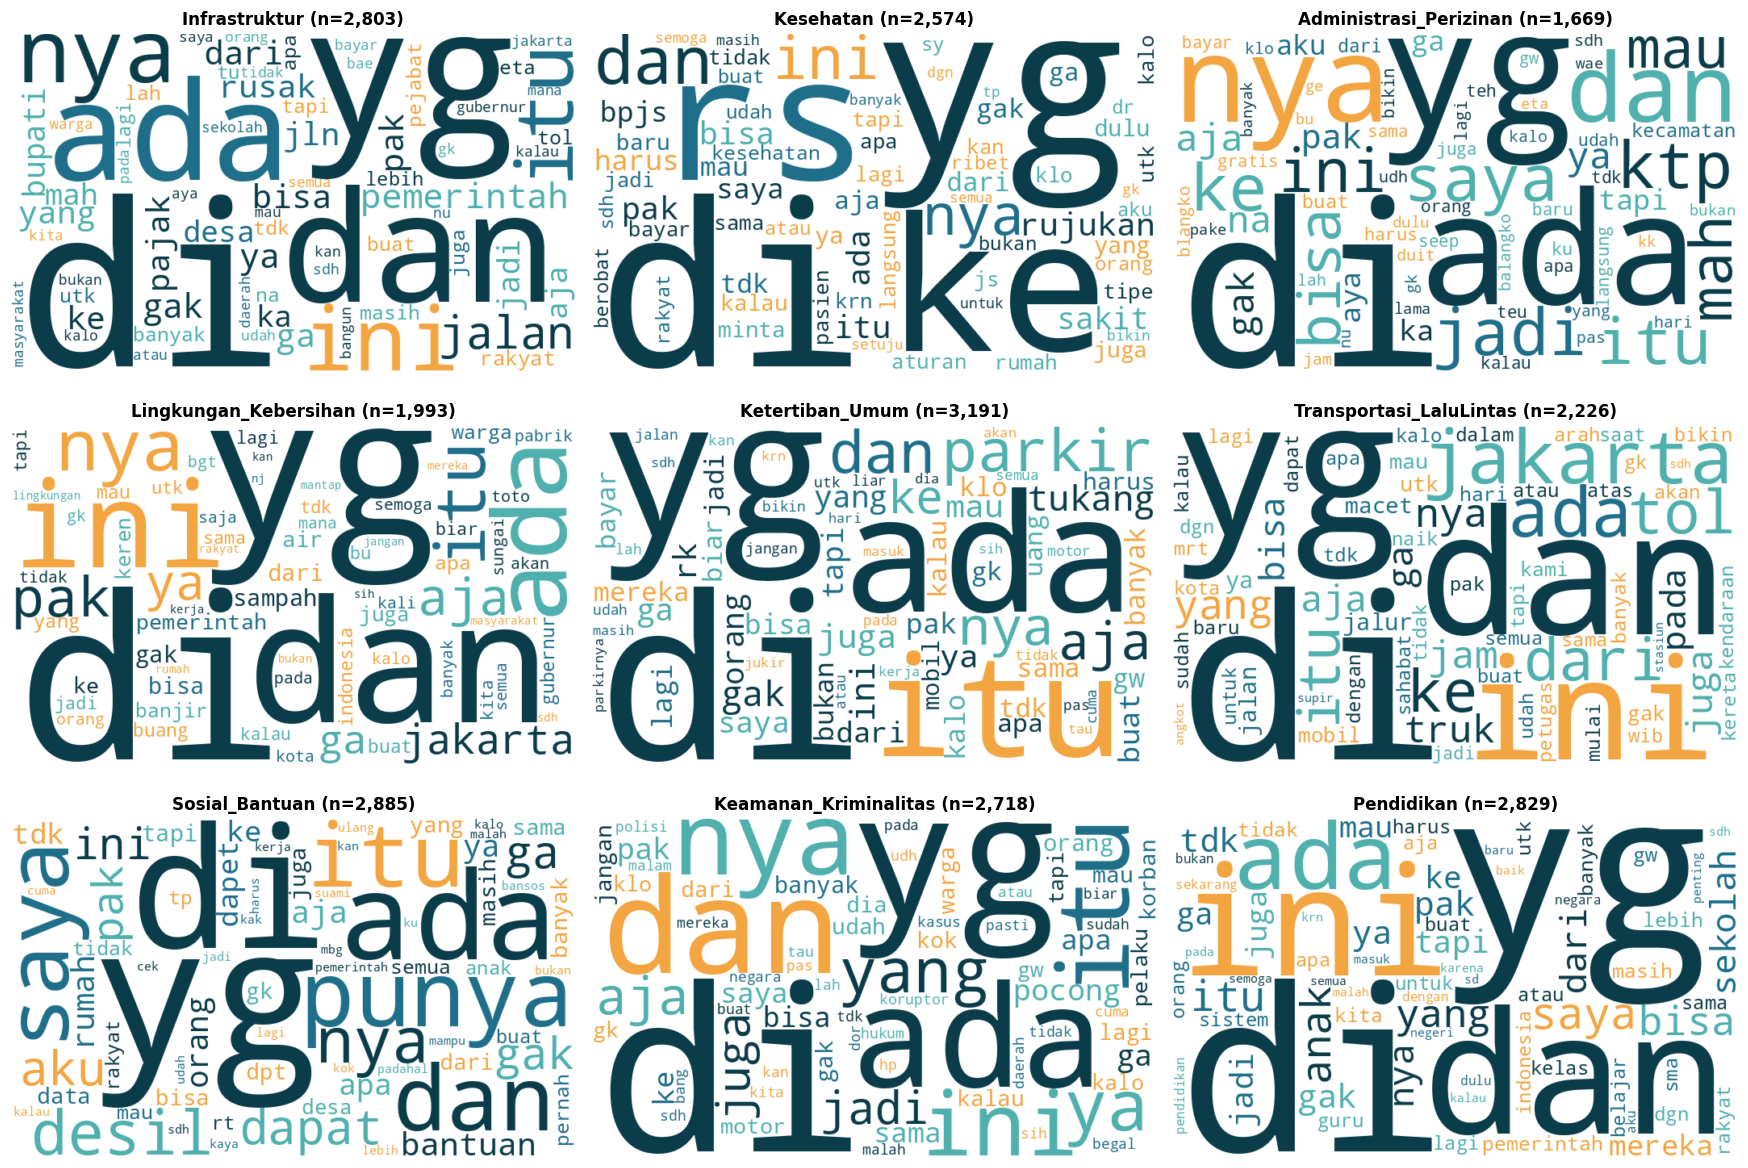

In [15]:
# ===== EDA 5 | Word cloud tiap pilar =====
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, c in zip(axes.ravel(), PILAR):
    m = eda[c] == 1
    cloud(ax, group_counter(m), f'{c} (n={m.sum():,})')
plt.tight_layout(); plt.show()

## 2.10 Wordcloud tiap Platform

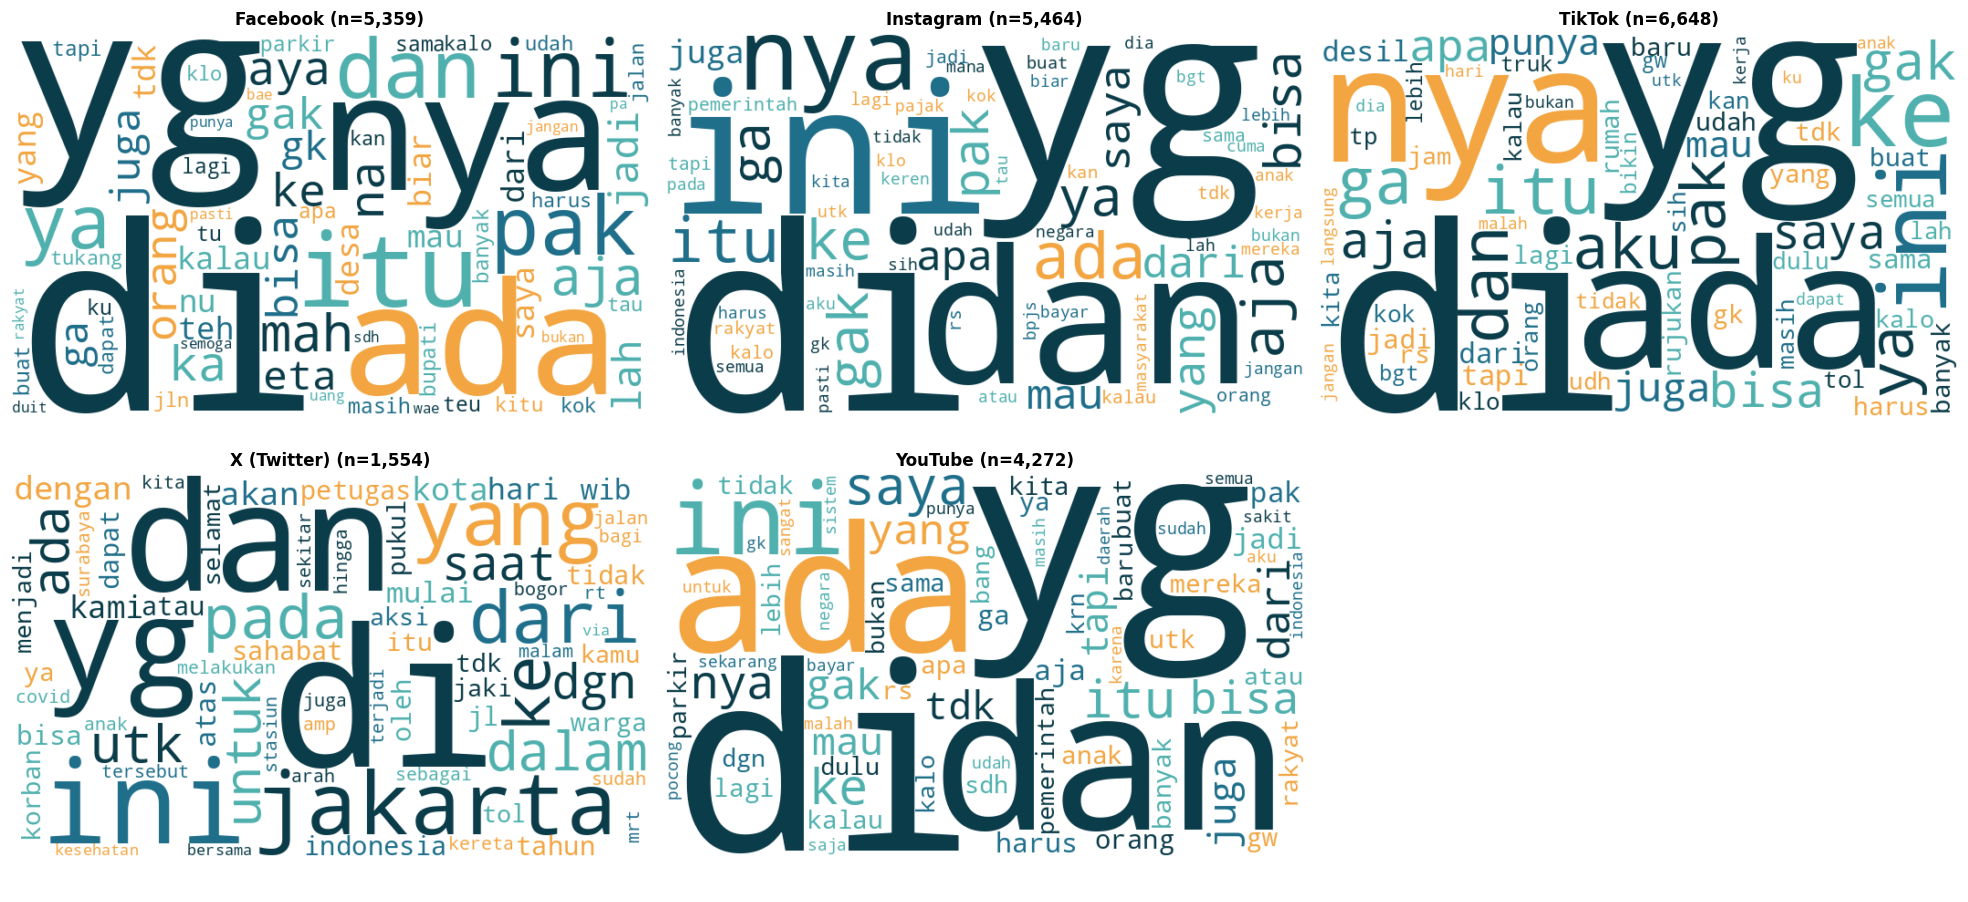

In [17]:
# ===== EDA 6 | Word cloud tiap platform =====
ncol = min(3, len(PLATFORMS)); nrow = int(np.ceil(len(PLATFORMS) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(6 * ncol, 4.2 * nrow), squeeze=False)
for ax in axes.ravel(): ax.axis('off')
for ax, p in zip(axes.ravel(), PLATFORMS):
    m = eda[PLAT_COL].astype(str) == p
    cloud(ax, group_counter(m), f'{p} (n={m.sum():,})')
plt.tight_layout(); plt.show()

## 2.11 Mesin Deteksi Noise

In [18]:
# ===== EDA 7a | Mesin deteksi noise (taksonomi Khan et al., 2025: Fig.1 & Tabel 2) =====
# Catatan: deteksi berbasis aturan/heuristik, bukan ground truth. Word deletion & real-word error tidak terdeteksi tanpa model bahasa.
import os, glob, urllib.request
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# ---------------------------------------------------------------------------------------------
# 0. LEKSIKON EKSTERNAL (menggantikan LAUGH, INFORMAL, ENG, ACRONYM_OK yang sebelumnya ditulis manual)
#    Setiap leksikon punya sumber, dan sumber yang terpakai dicetak di akhir blok ini.
# ---------------------------------------------------------------------------------------------
STRICT_LEXICON = False   # True = berhenti dengan error bila leksikon INFORMAL tidak ditemukan (tanpa fallback)
LEX_DIRS = ['/kaggle/input', '/kaggle/working', '.', './dataset', globals().get('OUTPUT_DIR', '.')]
CACHE_DIR = globals().get('OUTPUT_DIR', '.')
LEX_FILES = {'salsabila': 'colloquial-indonesian-lexicon.csv', 'ibrohim': 'new_kamusalay.csv'}
LEX_URLS = {
    'salsabila': 'https://raw.githubusercontent.com/nasalsabila/kamus-alay/master/colloquial-indonesian-lexicon.csv',
    'ibrohim': 'https://raw.githubusercontent.com/okkyibrohim/id-multi-label-hate-speech-and-abusive-language-detection/master/new_kamusalay.csv',
}
PROV = {}   # provenance: nama variabel -> (sumber, jumlah entri)

def find_lexicon(name):
    """Cari berkas leksikon di folder input; bila tidak ada, coba unduh (hanya jalan jika internet notebook aktif)."""
    fname = LEX_FILES[name]
    for d in LEX_DIRS:
        if d and os.path.isdir(d):
            hit = glob.glob(os.path.join(d, '**', fname), recursive=True)
            if hit: return hit[0]
    try:
        dst = os.path.join(CACHE_DIR, fname); os.makedirs(CACHE_DIR, exist_ok=True)
        with urllib.request.urlopen(LEX_URLS[name], timeout=15) as r, open(dst, 'wb') as f: f.write(r.read())
        return dst
    except Exception:
        return None

def read_pairs(path):
    """Baca CSV leksikon -> list (kata_informal, bentuk_formal). Kolom 1 & 2 dipakai; header dibuang bila ada."""
    for enc in ('utf-8', 'latin-1'):
        try:
            d = pd.read_csv(path, header=None, usecols=[0, 1], dtype=str, encoding=enc, on_bad_lines='skip', engine='python')
            break
        except Exception:
            d = None
    if d is None: return []
    d = d.dropna()
    if len(d) and str(d.iloc[0, 0]).strip().lower() in {'slang', 'alay', 'kata', 'colloquial'}: d = d.iloc[1:]
    return [(str(a).strip().lower(), str(b).strip().lower()) for a, b in d.itertuples(index=False)]

def build_informal(pairs):
    """Kata informal = kunci leksikon yang (a) satu token alfabet ASCII, (b) beda dari bentuk formalnya,
    (c) bukan bentuk formal milik entri lain (menyingkirkan kata ambigu yang sebenarnya baku)."""
    formal = {f for _, f in pairs}
    return {k for k, f in pairs if k.isascii() and k.isalpha() and len(k) >= 2 and k != f and k not in formal}

# --- 0a. LAUGH: pola ortografis tawa (bukan leksikon). Bentuk bersumber: hahaha, hehehe, wkwkwk, hiks
#         (Nurmala & Sinar, 2022, doi:10.22460/project.v5i4.p877-884; Widyatmoko & Kushartanti, doi:10.17509/ijal.v14i2.74897 untuk 'wkwk').
#         Bentuk tambahan (xixi, kwkw, awokwok) adalah konvensi umum medsos, bukan dari dua sumber di atas.
LAUGH = re.compile(r'^(?:a?(?:ha){2,}h?|(?:wk)+w?|(?:he){2,}h?|(?:hi){2,}h?|hi+k+s*|(?:xi){2,}x?|(?:kw)+k?|a?w[oa]?k(?:w?[oa]?k)+)$')
PROV['LAUGH'] = ('Pola regex dari Nurmala & Sinar (2022) + Widyatmoko & Kushartanti; xixi/kwkw/awokwok = konvensi umum', 'regex')

# --- 0b. INFORMAL: Colloquial Indonesian Lexicon (Salsabila et al., 2018, IALP; 3.592 kata, anotasi manual dari komentar Instagram).
#         Fallback: new_kamusalay.csv (Ibrohim & Budi, 2019, WOAH; ACL W19-3506).
INFORMAL, src = set(), None
for name, label in [('salsabila', 'Colloquial Indonesian Lexicon (Salsabila et al., 2018)'),
                    ('ibrohim', 'new_kamusalay.csv (Ibrohim & Budi, 2019)')]:
    p = find_lexicon(name)
    if p:
        INFORMAL = build_informal(read_pairs(p))
        if INFORMAL: src = f'{label} <- {p}'; break
if not INFORMAL:
    if STRICT_LEXICON: raise FileNotFoundError('Leksikon INFORMAL tidak ditemukan. Tambahkan dataset kamus alay ke Kaggle Input atau aktifkan internet.')
    INFORMAL = set("""nggak enggak ngga udah banget aja dong sih kok deh nih tuh lho loh kan gitu gini emang emg kayak kyk
    gue gw lu lo doang kali mah nya bokap nyokap gimana gmn kalo bgt""".split())
    src = 'FALLBACK daftar manual (BELUM dapat dipertanggungjawabkan; tambahkan leksikon Salsabila/Ibrohim)'
PROV['INFORMAL'] = (src, len(INFORMAL))

# --- 0c. ENG: stop word Inggris scikit-learn (daftar Glasgow IR; 318 kata). Dibuang: kata <3 huruf (bentrok dg Indonesia/slang),
#         singkatan non-kata, dan kata yang sama dengan stop word/slang Indonesia (STOP dari sel 4a, SLANG_DICT).
ID_AMBIG = {'per', 'via', 'con', 'den', 'ten', 'inc', 'ltd', 'etc', 'cant', 'couldnt', 'amoungst', 'fify', 'sincere', 'bill', 'mill'}
ID_WORDS = set(SLANG_DICT) | set(SLANG_DICT.values()) | set(globals().get('STOP', set()))
ENG = {w for w in ENGLISH_STOP_WORDS if len(w) >= 3 and w not in ID_AMBIG and w not in ID_WORDS}
PROV['ENG'] = ('sklearn.ENGLISH_STOP_WORDS (Glasgow IR stop list) - filter bentrok kata Indonesia', len(ENG))

# --- 0d. ACRONYM_OK: singkatan/akronim resmi lembaga & program layanan publik (dikurasi; tiap entri disertai kepanjangan agar bisa diaudit)
#         + entri SLANG_DICT yang bentuknya identik dg kepanjangannya (mis. bpjs, ktp).
ACRONYM_LEX = {
    'rt': 'rukun tetangga', 'rw': 'rukun warga', 'pln': 'perusahaan listrik negara', 'pdam': 'perusahaan daerah air minum',
    'tni': 'tentara nasional indonesia', 'polri': 'kepolisian negara republik indonesia', 'polres': 'kepolisian resor',
    'polsek': 'kepolisian sektor', 'polda': 'kepolisian daerah', 'dpr': 'dewan perwakilan rakyat', 'dprd': 'dewan perwakilan rakyat daerah',
    'apbd': 'anggaran pendapatan dan belanja daerah', 'apbn': 'anggaran pendapatan dan belanja negara', 'pns': 'pegawai negeri sipil',
    'asn': 'aparatur sipil negara', 'bumn': 'badan usaha milik negara', 'umkm': 'usaha mikro kecil dan menengah', 'bbm': 'bahan bakar minyak',
    'lpg': 'liquefied petroleum gas', 'rsud': 'rumah sakit umum daerah', 'ugd': 'unit gawat darurat', 'igd': 'instalasi gawat darurat',
    'icu': 'intensive care unit', 'puskesmas': 'pusat kesehatan masyarakat', 'posyandu': 'pos pelayanan terpadu', 'bpom': 'badan pengawas obat dan makanan',
    'jkn': 'jaminan kesehatan nasional', 'kis': 'kartu indonesia sehat', 'kip': 'kartu indonesia pintar', 'nik': 'nomor induk kependudukan',
    'sktm': 'surat keterangan tidak mampu', 'stnk': 'surat tanda nomor kendaraan', 'bpkb': 'buku pemilik kendaraan bermotor',
    'npwp': 'nomor pokok wajib pajak', 'pbb': 'pajak bumi dan bangunan', 'imb': 'izin mendirikan bangunan', 'pbg': 'persetujuan bangunan gedung',
    'kpk': 'komisi pemberantasan korupsi', 'kpu': 'komisi pemilihan umum', 'bawaslu': 'badan pengawas pemilihan umum',
    'bnpb': 'badan nasional penanggulangan bencana', 'bpbd': 'badan penanggulangan bencana daerah', 'bmkg': 'badan meteorologi klimatologi dan geofisika',
    'basarnas': 'badan nasional pencarian dan pertolongan', 'bappeda': 'badan perencanaan pembangunan daerah', 'dishub': 'dinas perhubungan',
    'dinkes': 'dinas kesehatan', 'disdik': 'dinas pendidikan', 'dukcapil': 'kependudukan dan pencatatan sipil', 'pupr': 'pekerjaan umum dan penataan ruang',
    'kemenkes': 'kementerian kesehatan', 'kemendikbud': 'kementerian pendidikan dan kebudayaan', 'kemenag': 'kementerian agama',
    'kemenhub': 'kementerian perhubungan', 'tps': 'tempat pembuangan sementara', 'tpa': 'tempat pembuangan akhir', 'tpst': 'tempat pengolahan sampah terpadu',
    'odgj': 'orang dengan gangguan jiwa', 'kdrt': 'kekerasan dalam rumah tangga', 'ppdb': 'penerimaan peserta didik baru',
    'paud': 'pendidikan anak usia dini', 'sd': 'sekolah dasar', 'smp': 'sekolah menengah pertama', 'sma': 'sekolah menengah atas', 'smk': 'sekolah menengah kejuruan',
}
ACRONYM_OK = {k for k, v in SLANG_DICT.items() if k == v} | set(ACRONYM_LEX)
PROV['ACRONYM_OK'] = ('Kurasi manual singkatan resmi lembaga/program publik (+ identitas SLANG_DICT); tiap entri punya kepanjangan', len(ACRONYM_OK))

print('=== PROVENANCE LEKSIKON ===')
for k, (s, n) in PROV.items(): print(f'  {k:<10}: {n!s:>6} | {s}')
print('  Contoh INFORMAL :', sorted(INFORMAL)[:12])
print('  Contoh ENG      :', sorted(ENG)[:12])

# ---------------------------------------------------------------------------------------------
# 1. MESIN DETEKSI NOISE (logika tidak berubah; hanya sumber leksikon di atas yang diganti)
# ---------------------------------------------------------------------------------------------
VOW = set('aiueo')
CYR_TABLE = str.maketrans(CYRILLIC_TO_LATIN)

def prep(t):
    t = unicodedata.normalize('NFKC', t).translate(CYR_TABLE)
    return MENT_RE.sub(' ', URL_RE.sub(' ', t))

# 1. Vocabulary frekuen (>=5) sebagai referensi "kata wajar" dari korpus sendiri
FREQ_RAW = Counter(w for t in eda[TEXT_COL] for w in re.findall(r'[a-z]+', prep(t).lower()))
VOCAB = {w for w, c in FREQ_RAW.items() if c >= 5 and len(w) >= 2}

# 2. Indeks edit-distance-1 (teknik SymSpell) untuk deteksi typo
def deletes(w): return {w[:i] + w[i+1:] for i in range(len(w))}
DEL_IDX = defaultdict(set)
for v in VOCAB:
    DEL_IDX[v].add(v)
    for d in deletes(v): DEL_IDX[d].add(v)
def is_typo(w):
    cands = set(DEL_IDX.get(w, ()))
    for d in deletes(w): cands |= DEL_IDX.get(d, set())
    return any(c != w for c in cands)

# 3. Bigram karakter untuk deteksi gibberish
BG, UG = Counter(), Counter()
for w in VOCAB:
    s = '^' + w + '$'
    for a, b in zip(s, s[1:]): BG[a + b] += 1; UG[a] += 1
def lm_score(w):
    s = '^' + w + '$'
    return np.mean([np.log((BG[a + b] + 1) / (UG[a] + 28)) for a, b in zip(s, s[1:])])
LM_THR = np.percentile([lm_score(w) for w in VOCAB], 1)
KEYS = ['qwertyuiop', 'asdfghjkl', 'zxcvbnm']
KEY4 = {r[i:i+4] for r in KEYS + [k[::-1] for k in KEYS] for i in range(len(r) - 3)}

@functools.lru_cache(None)
def gib_rule(w):
    if any(w[i:i+4] in KEY4 for i in range(len(w) - 3)): return 'Keyboard mash'
    if re.search(r'[^aiueo]{5,}', w): return 'Rentetan konsonan'
    if len(w) >= 5 and FREQ_RAW[w] <= 2 and lm_score(w) < LM_THR: return 'Pola huruf tak wajar'
    return None

# 4. Klasifikasi per token
@functools.lru_cache(None)
def classify(o):
    w = o.lower(); vowel = any(c in VOW for c in w)
    if w.isdigit() or PROTECT_PATTERN.match(w): return None
    if REDUP_PATTERN.match(w): return 'phonetic'
    if any(c.isalpha() for c in w) and any(c.isdigit() for c in w):
        return 'visual' if any(c in LEET_MAP for c in w) else None
    if re.search(r'([a-z])\1{2,}', w): return 'enlargement'
    if LAUGH.match(w): return None
    if w in ACRONYM_OK or (o.isupper() and 2 <= len(w) <= 6 and not vowel): return 'alphabetism'
    if w in SLANG_DICT or (2 <= len(w) <= 5 and not vowel): return 'shortening'
    if w in INFORMAL: return 'contraction'
    if len(w) >= 4 and w not in VOCAB:
        if gib_rule(w): return 'gibberish'
        if is_typo(w): return 'typo'
    return None

INTENT = ['shortening', 'alphabetism', 'enlargement', 'contraction', 'phonetic', 'visual', 'code_mixed']
UNINT  = ['typo', 'boundary', 'gibberish']
ARTIF  = ['url', 'mention', 'hashtag', 'emoji', 'number', 'caps_emph', 'punct_rep']
NTYPES = INTENT + UNINT + ARTIF
NOISE_TOK = ['shortening', 'enlargement', 'contraction', 'phonetic', 'visual', 'typo', 'gibberish']  # untuk noise density
BOUND = re.compile(r'[a-z]{2}[,!?;][A-Za-z]{2}|[a-z]{2}\.(?!com|co\b|id\b|go\b|net|org|my\b)[A-Za-z]{2}|[a-z][A-Z][a-z]')

# 5. Analisis per teks
def analyze(t0):
    t = prep(t0); toks = re.findall(r'[A-Za-z0-9]+', t)
    labs = [(o, classify(o)) for o in toks]
    c = Counter(l for _, l in labs if l)
    if any(ch in CYRILLIC_TO_LATIN for ch in t0) or any(ch.isalpha() and ord(ch) > 127 and unicodedata.normalize('NFKC', ch) != ch for ch in t0):
        c['visual'] += 1
    c['url'], c['mention'], c['hashtag'] = len(URL_RE.findall(t0)), len(MENT_RE.findall(t0)), len(HASH_RE.findall(t0))
    c['emoji'] = emoji.emoji_count(t0)
    c['number'] = sum(o.isdigit() for o in toks)
    c['caps_emph'] = sum(o.isalpha() and o.isupper() and len(o) >= 4 and any(ch in 'AIUEO' for ch in o) and o.lower() not in ACRONYM_OK for o in toks)
    c['punct_rep'] = len(re.findall(r'[!?]{2,}', t0))
    c['boundary'] = len(BOUND.findall(HASH_RE.sub(' ', MENT_RE.sub(' ', URL_RE.sub(' ', t0)))))
    c['code_mixed'] = int(sum(o.lower() in ENG for o in toks) >= 2)
    return c, [o.lower() for o, l in labs if l == 'gibberish'], sum(not o.isdigit() for o in toks)

res = [analyze(t) for t in eda[TEXT_COL]]
NOISE = pd.DataFrame([r[0] for r in res], index=eda.index).reindex(columns=NTYPES).fillna(0).astype(int)
eda['gib_tokens'] = [r[1] for r in res]
eda['n_tok'] = [r[2] for r in res]
eda['noise_pct'] = NOISE[NOISE_TOK].sum(axis=1) / eda['n_tok'].clip(lower=1) * 100
print(f'Noise engine selesai | {len(eda):,} teks | rata-rata noise density: {eda.noise_pct.mean():.2f}% token')

# 6. Audit kecocokan leksikon dengan korpus (cek sanity; bukan ground truth)
_tok = Counter(o.lower() for t in eda[TEXT_COL] for o in re.findall(r'[A-Za-z]+', prep(t)))
for nm, lex in [('INFORMAL', INFORMAL), ('ENG', ENG), ('ACRONYM_OK', ACRONYM_OK)]:
    hit = sum(c for w, c in _tok.items() if w in lex)
    print(f'  {nm:<10}: {hit / max(sum(_tok.values()), 1) * 100:5.2f}% token korpus | top: {[w for w, _ in Counter({w: c for w, c in _tok.items() if w in lex}).most_common(8)]}')

=== PROVENANCE LEKSIKON ===
  LAUGH     :  regex | Pola regex dari Nurmala & Sinar (2022) + Widyatmoko & Kushartanti; xixi/kwkw/awokwok = konvensi umum
  INFORMAL  :   3883 | Colloquial Indonesian Lexicon (Salsabila et al., 2018) <- /kaggle/input/datasets/eaganrainmahasin/colloquial-indonesian-lexicon-csv/colloquial-indonesian-lexicon.csv
  ENG       :    273 | sklearn.ENGLISH_STOP_WORDS (Glasgow IR stop list) - filter bentrok kata Indonesia
  ACRONYM_OK:     71 | Kurasi manual singkatan resmi lembaga/program publik (+ identitas SLANG_DICT); tiap entri punya kepanjangan
  Contoh INFORMAL : ['aaaaaaakkk', 'aaaaahhhh', 'aaaammmiiiinnnn', 'aaahh', 'aaamiiin', 'aaamiiinnn', 'aaamin', 'aahh', 'aama', 'aamien', 'aamiiiiinnn', 'aamiiiinnnnn']
  Contoh ENG      : ['about', 'above', 'across', 'after', 'afterwards', 'again', 'against', 'all', 'almost', 'alone', 'along', 'already']
Noise engine selesai | 23,297 teks | rata-rata noise density: 26.52% token
  INFORMAL  : 11.58% token korpus | top: 

## 2.12 Cek Distribusi Noise

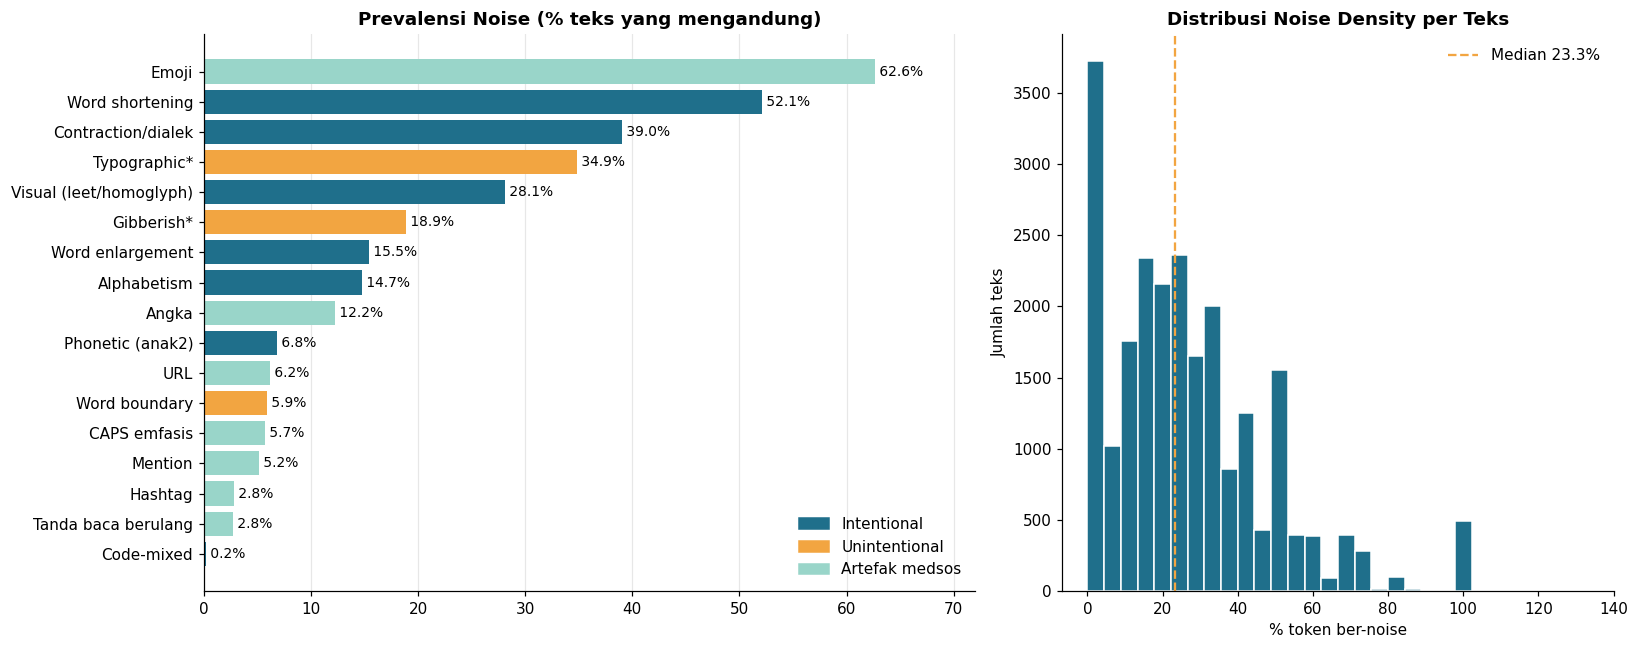

* Typographic & Gibberish = estimasi heuristik berbasis vocabulary korpus.
Teks dengan >=1 noise linguistik: 86.1%


In [19]:
# ===== EDA 7 | Distribusi noise keseluruhan =====
LBL = {'shortening': 'Word shortening', 'alphabetism': 'Alphabetism', 'enlargement': 'Word enlargement',
       'contraction': 'Contraction/dialek', 'phonetic': 'Phonetic (anak2)', 'visual': 'Visual (leet/homoglyph)',
       'code_mixed': 'Code-mixed', 'typo': 'Typographic*', 'boundary': 'Word boundary', 'gibberish': 'Gibberish*',
       'url': 'URL', 'mention': 'Mention', 'hashtag': 'Hashtag', 'emoji': 'Emoji', 'number': 'Angka',
       'caps_emph': 'CAPS emfasis', 'punct_rep': 'Tanda baca berulang'}
CAT_COL = {**{k: PAL['main'] for k in INTENT}, **{k: PAL['accent'] for k in UNINT}, **{k: PAL['light'] for k in ARTIF}}

prev = ((NOISE > 0).mean() * 100).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.4, 1]})
ax[0].barh([LBL[k] for k in prev.index], prev.values, color=[CAT_COL[k] for k in prev.index])
for i, v in enumerate(prev.values): ax[0].text(v, i, f' {v:.1f}%', va='center', fontsize=9)
ax[0].set_title('Prevalensi Noise (% teks yang mengandung)'); ax[0].margins(x=.15); ax[0].grid(axis='x', alpha=.3); ax[0].set_axisbelow(True)
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=PAL['main'], label='Intentional'), Patch(color=PAL['accent'], label='Unintentional'),
                      Patch(color=PAL['light'], label='Artefak medsos')], frameon=False, loc='lower right')

ax[1].hist(eda.noise_pct, bins=30, color=PAL['main'], edgecolor='white')
ax[1].axvline(eda.noise_pct.median(), color=PAL['accent'], ls='--', label=f'Median {eda.noise_pct.median():.1f}%')
ax[1].set_title('Distribusi Noise Density per Teks'); ax[1].set_xlabel('% token ber-noise'); ax[1].set_ylabel('Jumlah teks'); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()
print('* Typographic & Gibberish = estimasi heuristik berbasis vocabulary korpus.')
print(f'Teks dengan >=1 noise linguistik: {(NOISE[INTENT+UNINT].sum(axis=1) > 0).mean()*100:.1f}%')

## 2.13 Mesin Distribusi Noise Per Group

In [21]:
# ===== EDA 8 & 9 | Fungsi distribusi noise per grup =====
ORDER = INTENT + UNINT + ARTIF

def noise_by_group(masks, title):
    names = list(masks)
    prev = pd.DataFrame({n: (NOISE[m] > 0).mean() * 100 for n, m in masks.items()}).T[ORDER]
    prev.columns = [LBL[c] for c in ORDER]
    rel = prev / prev.max().replace(0, 1)           # warna relatif per kolom, angka = % asli
    fig, ax = plt.subplots(1, 2, figsize=(17, 0.55 * len(names) + 3.5), gridspec_kw={'width_ratios': [4, 1.1]})
    sns.heatmap(rel, annot=prev.round(1).astype(str), fmt='', cmap=CMAP, cbar=False, linewidths=.5, linecolor='white', ax=ax[0])
    ax[0].set_title(f'Prevalensi Noise per {title} (% teks, warna relatif per kolom)'); ax[0].set_ylabel('')
    plt.setp(ax[0].get_xticklabels(), rotation=45, ha='right')
    data = [eda.loc[m, 'noise_pct'] for m in masks.values()]
    bp = ax[1].boxplot(data, vert=False, showfliers=False, patch_artist=True, medianprops={'color': PAL['accent'], 'lw': 2})
    ax[1].set_yticklabels(names)
    for b in bp['boxes']: b.set_facecolor(PAL['light']); b.set_edgecolor(PAL['dark'])
    ax[1].invert_yaxis(); ax[1].set_title('Noise Density (% token)'); ax[1].grid(axis='x', alpha=.3)
    plt.tight_layout(); plt.show()
    return prev

## 2.14 Distribusi Noise Tiap Pilar

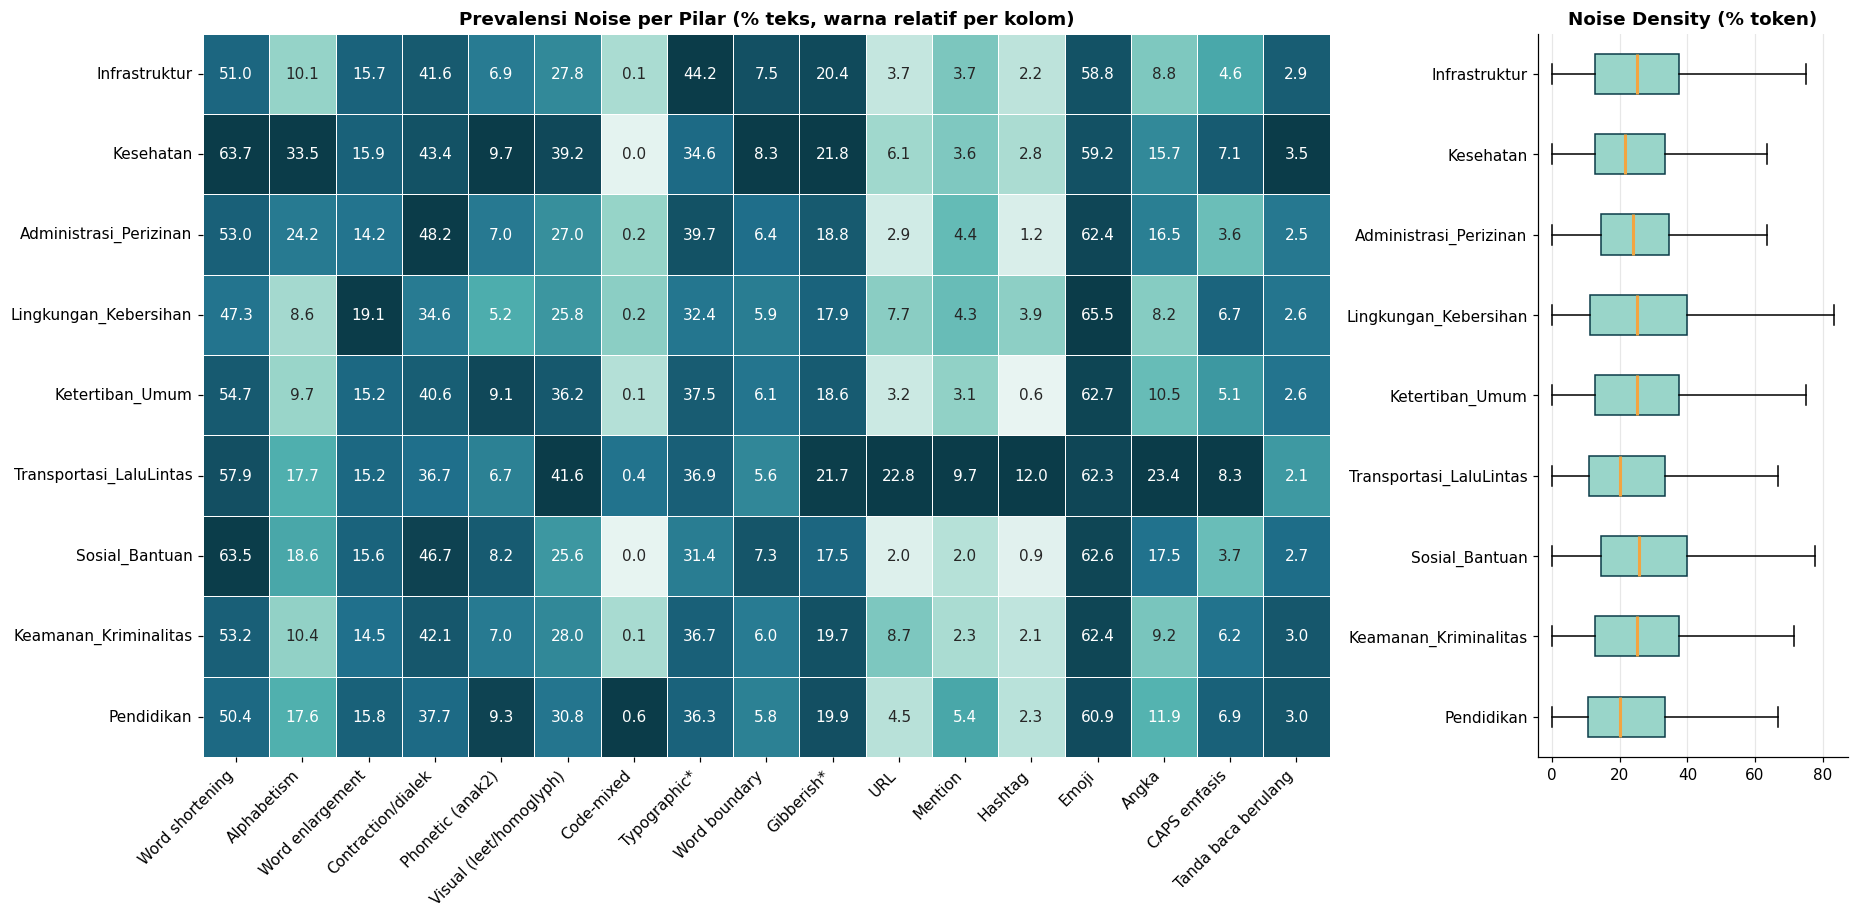

In [22]:
# ===== EDA 8 | Distribusi noise tiap pilar =====
prev_pilar = noise_by_group({c: eda[c] == 1 for c in PILAR}, 'Pilar')

## 2.15 Distribusi Noise Tiap Platform

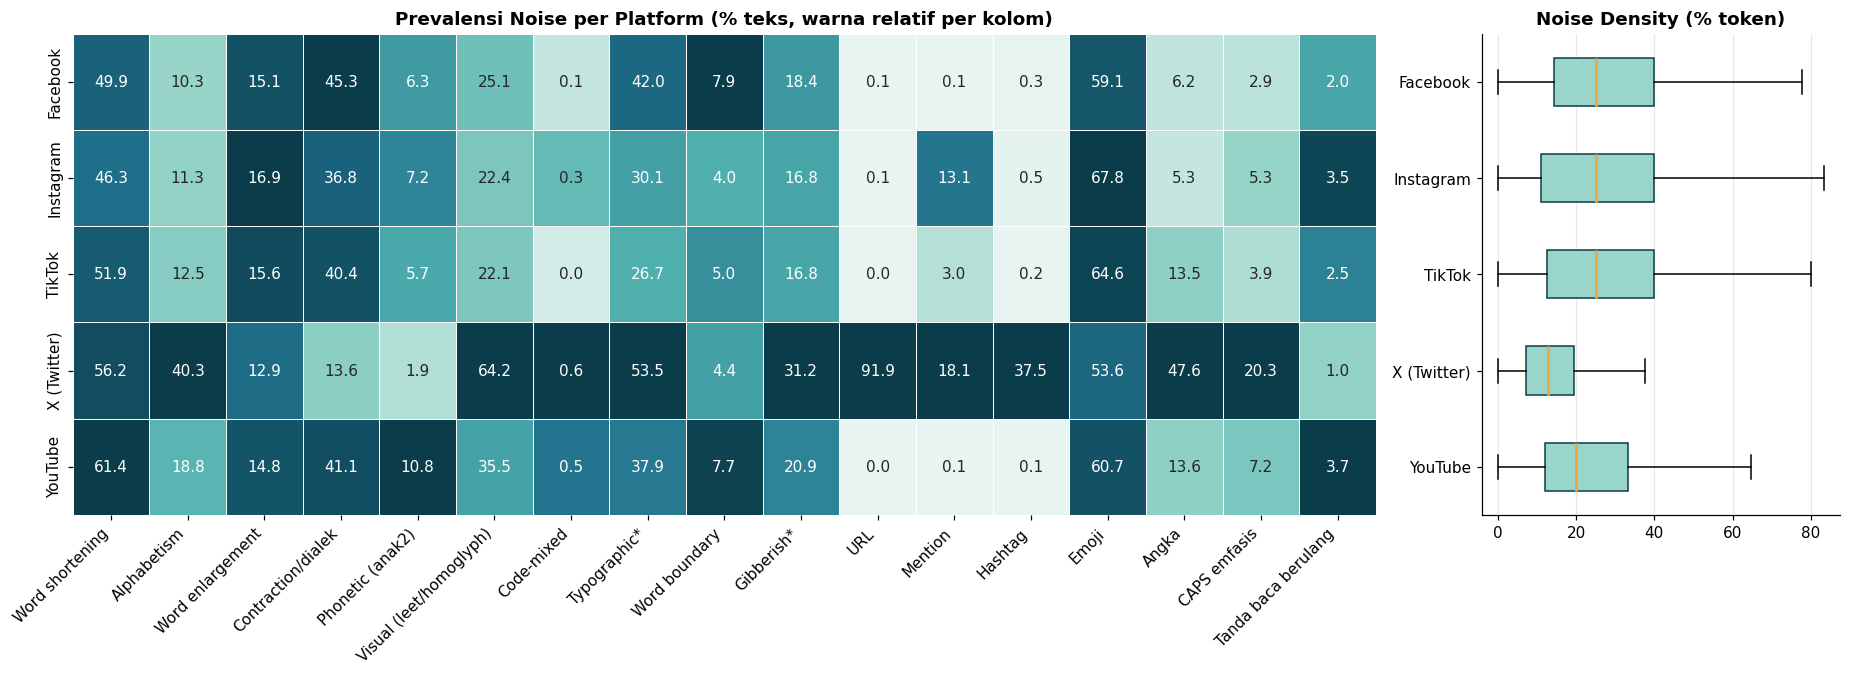

In [23]:
# ===== EDA 9 | Distribusi noise tiap platform =====
prev_plat = noise_by_group({p: eda[PLAT_COL].astype(str) == p for p in PLATFORMS}, 'Platform')

## 2.16 Pengecekan Kata Acak Tanpa Makna

Token gibberish: 5,123 (1.49% token) | Unik: 4,190 | Muncul di 4,404 teks (18.90%)


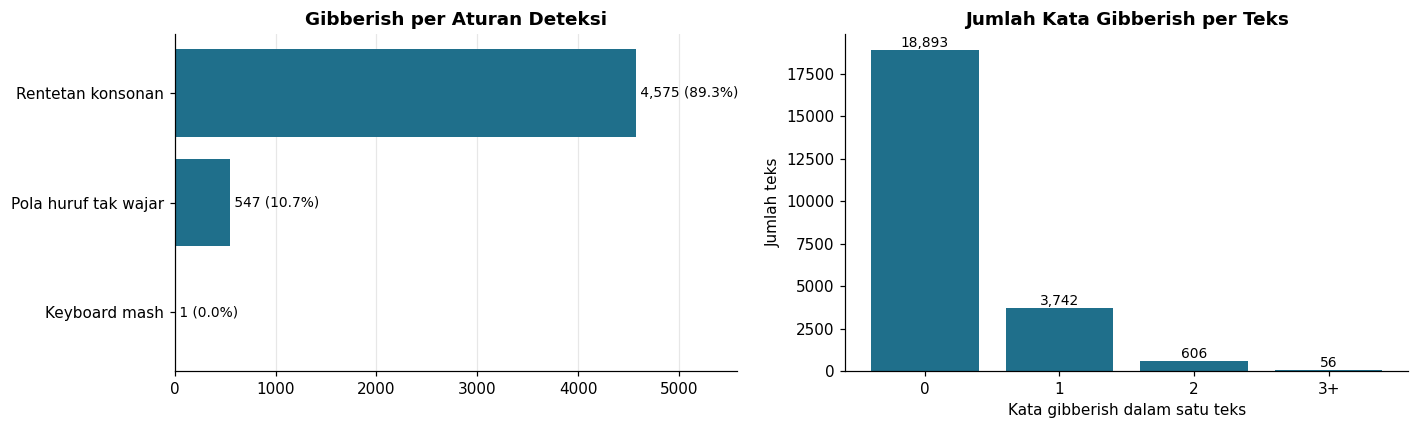


Contoh token gibberish (terbanyak):
               frekuensi             aturan
apcmltvly              4  Rentetan konsonan
vdpsdl                 4  Rentetan konsonan
wdqjhudqj              4  Rentetan konsonan
crwmjt                 4  Rentetan konsonan
gfslxf                 4  Rentetan konsonan
pxqjnlq                4  Rentetan konsonan
umvbzq                 4  Rentetan konsonan
inrfsf                 4  Rentetan konsonan
fqmfrizqnqqfm          4  Rentetan konsonan
fqfxfs                 4  Rentetan konsonan
vhwlds                 4  Rentetan konsonan
pdqwds                 4  Rentetan konsonan
minlrtj                4  Rentetan konsonan
alwtyr                 4  Rentetan konsonan
umvmzqui               4  Rentetan konsonan
rjwjpf                 4  Rentetan konsonan
yzpfsl                 4  Rentetan konsonan
crynlnana              4  Rentetan konsonan
frznxva                4  Rentetan konsonan
pjqzfw                 4  Rentetan konsonan
gnfxfsdf               4  Rentetan kons

In [24]:
# ===== EDA 10 | Kata acak tanpa makna (gibberish) =====
gib_all = list(itertools.chain.from_iterable(eda['gib_tokens']))
n_tok_all = int(eda['n_tok'].sum()); n_gib = len(gib_all)
n_txt = int((eda['gib_tokens'].map(len) > 0).sum())
print(f'Token gibberish: {n_gib:,} ({n_gib/max(n_tok_all,1)*100:.2f}% token) | Unik: {len(set(gib_all)):,} | Muncul di {n_txt:,} teks ({n_txt/len(eda)*100:.2f}%)')

rule = pd.Series(Counter(gib_rule(w) for w in gib_all)).sort_values()
per_txt = eda['gib_tokens'].map(len).clip(upper=3).value_counts().reindex([0, 1, 2, 3], fill_value=0)
per_txt.index = ['0', '1', '2', '3+']

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
barh(ax[0], rule if len(rule) else pd.Series({'-': 0}), 'Gibberish per Aturan Deteksi', total=max(n_gib, 1))
ax[1].bar(per_txt.index, per_txt.values, color=PAL['main'])
for i, v in enumerate(per_txt.values): ax[1].text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
ax[1].set_title('Jumlah Kata Gibberish per Teks'); ax[1].set_xlabel('Kata gibberish dalam satu teks'); ax[1].set_ylabel('Jumlah teks')
plt.tight_layout(); plt.show()

print('\nContoh token gibberish (terbanyak):')
print(pd.Series(Counter(gib_all)).sort_values(ascending=False).head(25).to_frame('frekuensi').assign(aturan=lambda d: [gib_rule(w) for w in d.index]))

## 2.17 Ambil Semua Emoji

Total emoji: 58,068 | Unik: 548 | Teks beremoji: 36,332 (62.4%)

Seluruh emoji unik:
😂🙏😡🙄🤦‍♂️❗⚠️🛵💥‼️👀🛑😭🤣👍🔥😢😅😁👏🥰🥺❤️❤🗿🤲😮🤭😊😍💪😳🤔🙏🏻😀😌😇🙌😏🥹😄😆😔😹🥲👍🏻🤦🎉💔😃🇮🇩😩☺️😎🤪😥🐕✅🙂👎😫🙈🤩😑🤗😝👌♥️😜😠🫣😱🤲🏻💩🥳🇲🇨➖🥱😘🫡😤😞✨🙏🏼💯🙃❌😬👊😓✊🫢🤬⭐👍🏼🥴🤝💸😒🚦💀🤤🤧🤦‍♀️😉☺🫠👏🏻✌️🤍💙🫰🤨🤫🤯🫶😋💨🤮😵‍💫🥀👇😰🙌🏻🇵🇸🚨😪🫵🏻💪🏻👈🧐😲☝️❎😮‍💨💃🤦🏻👎🏻💕🤟🙏🏽😈📸😛😐✌🤡😖😶🌹🎥👌🏻💗🙏🏿⚡👍🏽❓🐒🤕🖕☹️💖🫶🏻🤦🏻‍♂️🕺🫵💚👉🩵😴🫩🤑🔨💓🤜🚀💰🐸🐶😗🧠📍☝🤛👻🤷🫧🙏🏾☝🏼🫥👹🤘👆🤏😺🚎🕊️📈✔️🤷‍♂️📷☝🏻🙋‍♀️📝🙊🚓💋💫👮👍🏾🎞🤴👸📹🪣❤️‍🩹😣💝😟🤢💵🗣💜🕌🤦🏻‍♀️💞🧡🥵🤓📌💬👑🐈‍⬛🐷🗓☕🐔🙂‍↔️👧🤙🏻🥶🐖🤞🤝🏻🌟🫶🏼📚💡👺🚫😷🩷💤🏃🏻🏴‍☠️🙂‍↕️🤐🥊🧒🧕🌷🧤🤷🏻‍♂️😚⁉️👋🏻🚯🤏🏻💛🤒✊🏻🌏🌊🐟⬇️😕🥸🤷🏾‍♂️🌍♻️🏃‍♂️♻🏢😧🧼👋🤦🏼‍♂️💐🌸👩🌚🌻🐀🦫🧹😨⚠🦖🚑🇳🇱🍻🦥🙇‍♂️📄🌿⛽❔☑️🪠♥®👽🧽🎀🇮🇳🐃👆🏻🌳😵🇰🇷💼🆙🫂🫰🏼🌴🫰🏻🍃🕺🏼👕☁️🙁1️⃣2️⃣3️⃣🥩🚗🇦🇱🩴💪🏿🫨🍓🎁🤦🏼‍♀️💃🏻😻📢👇🏻☠️👵🔎🍍🍉🥭🫤🩳🔜🍥📣🚉🍼📱🥦🎬🙇🏻‍♂️☀️🦆🫦👾👴👦👨🍤💾🔁✋🏽👎🏼🌠🐭✌🏻🎆💁‍♂️🕳️🙉🍣👩🏻↗️🕺🏻🐿️🛟💦🛞💁🏼‍♂️🚍💁🏻‍♀️🦁🧜‍♀️🦊🐢4️⃣🔴🦦🐨👯‍♀️😶‍🌫️🔏🍭😽👍🏿😿👨‍👩‍👧‍👧🤘🏻🤦‍♂❣️🧶😯➡️🪸🤲🏽🌺🖼️🙇🌧🧘🏻‍♀️🐧✊🏼🦈🐊👤™🍎🧸🐣🤦🏿🩹🕊✌🏽🔳❕🎋🇧🇩🇵🇰🪄🅿🚧2⃣1⃣🌈🍄🧚🏻‍♀️‼🐝🏥🎐🏝️🪓🛂👈🏻📽📽️🩺🦩🖕🏻🔹🇵🇭🤌🔓🌐📞📅🎯💧🚁🫪⏳⚖5⃣4⃣😶‍🌫3⃣🥛🦅👊🏻☑✖️🦋🇲🇪🍆🇲🇲🇰🇭🧢🤚🏻✋🏻👳🏻🌡️🇲🇾🖐️🆘🙌🏼🤲🏼🏳👥👌🏼🤌🏼👮🏼‍♂️🖇️🙋🍛🦹💪🏼🗣️⚜️🦮👿🫯🕸️🏃👐🐱🧑‍🦼🩸🤸🏻‍♀️🏋🏻‍♀️🌙✊🏿🤙🏼⛩🏍🧔🏾‍♂️🚙🚏🏘🧕🏻🚬🤏🏼🙆‍♀️🩰🌵🥂💆‍♂️🤷🏼‍♂️🌎🩶🔆🔑💌🦸🛐➡


,emoji,frekuensi,n_teks,nama
0,😂,6210,3205,wajah gembira berurai air mata
1,🙏,3967,3488,melipat tangan
2,😡,2904,2782,wajah sangat marah
3,🙄,2799,2763,wajah dengan mata ke atas
4,🤦‍♂️,2799,2787,pria tepuk jidat
5,❗,2759,2759,tanda seru merah
6,⚠️,2736,2736,peringatan
7,🛵,2682,2682,motor skuter
8,💥,2656,2653,tabrakan
9,‼️,2647,2645,tanda seru ganda


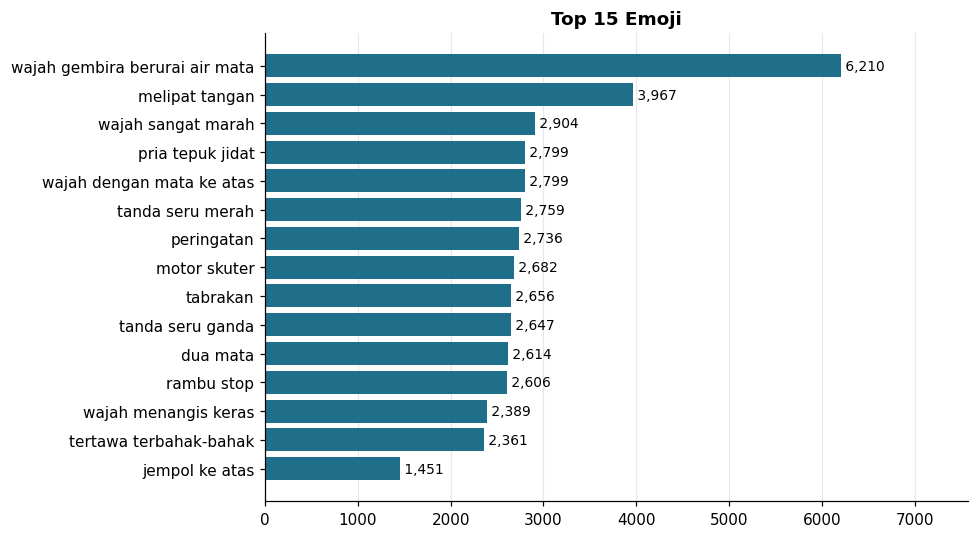

In [25]:
# ===== EDA 11 | Seluruh emoji (train + test, Teks & caption unik) =====
caps = pd.concat([train_df[CAP_COL], test_df[CAP_COL]]).dropna().astype(str).drop_duplicates()
corpus = pd.concat([train_df[TEXT_COL], test_df[TEXT_COL], caps]).dropna().astype(str)

# 1. Ekstraksi hanya emoji
emo_per_text = corpus.map(lambda t: [e['emoji'] for e in emoji.emoji_list(t)])
emo_cnt = Counter(itertools.chain.from_iterable(emo_per_text))
emo_docs = Counter(e for lst in emo_per_text for e in set(lst))

def emo_name(e):
    try:
        n = emoji.demojize(e, language='id').strip(':').replace('_', ' ')
        return n if n != e else emoji.EMOJI_DATA.get(e, {}).get('en', e).strip(':').replace('_', ' ')
    except Exception: return e

emo_df = pd.DataFrame({'emoji': list(emo_cnt), 'frekuensi': list(emo_cnt.values())})
emo_df['n_teks'] = emo_df['emoji'].map(emo_docs)
emo_df['nama'] = emo_df['emoji'].map(emo_name)
emo_df = emo_df.sort_values('frekuensi', ascending=False).reset_index(drop=True)

print(f'Total emoji: {emo_df.frekuensi.sum():,} | Unik: {len(emo_df):,} | Teks beremoji: {sum(len(l)>0 for l in emo_per_text):,} ({sum(len(l)>0 for l in emo_per_text)/len(corpus)*100:.1f}%)')
print('\nSeluruh emoji unik:\n' + ''.join(emo_df.emoji))
display(emo_df.head(25))

# 2. Visual top 15 (label nama, karena glyph emoji tidak selalu ter-render di matplotlib)
top = emo_df.head(15).set_index('nama')['frekuensi']
fig, ax = plt.subplots(figsize=(9, 5)); barh(ax, top, 'Top 15 Emoji'); plt.tight_layout(); plt.show()

## 2.18 Audit Kualitas Data

               train_null  test_null
Judul_Caption        1554          0


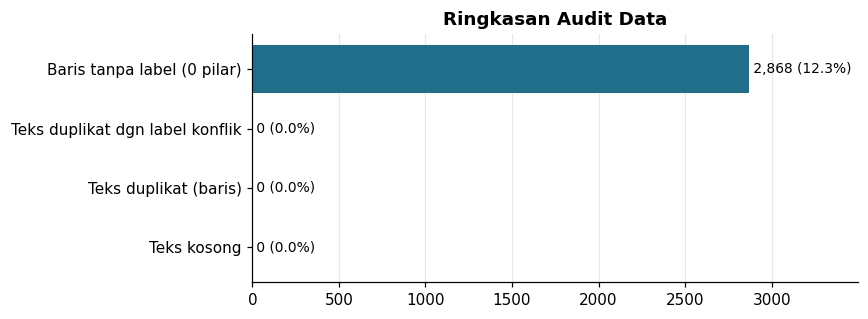

In [26]:
# ===== EDA 12a | Audit kualitas data (missing, duplikat, label konflik) =====
shared = [c for c in train_df.columns if c in test_df.columns]
audit = pd.DataFrame({'train_null': train_df[shared].isna().sum(), 'test_null': test_df[shared].isna().sum()})
print(audit[(audit > 0).any(axis=1)] if (audit > 0).any().any() else 'Tidak ada missing value.')

dup = eda.duplicated(subset=[TEXT_COL], keep=False)
conflict = eda[dup].groupby(TEXT_COL)[PILAR].nunique().gt(1).any(axis=1).sum()
audit_s = pd.Series({'Teks kosong': (eda[TEXT_COL].str.strip() == '').sum(),
                     'Teks duplikat (baris)': int(dup.sum()),
                     'Teks duplikat dgn label konflik': int(conflict),
                     'Baris tanpa label (0 pilar)': int((eda[PILAR].sum(axis=1) == 0).sum())})
fig, ax = plt.subplots(figsize=(8, 3)); barh(ax, audit_s, 'Ringkasan Audit Data', total=len(eda)); plt.tight_layout(); plt.show()

## 2.19 Kardinalitas Label

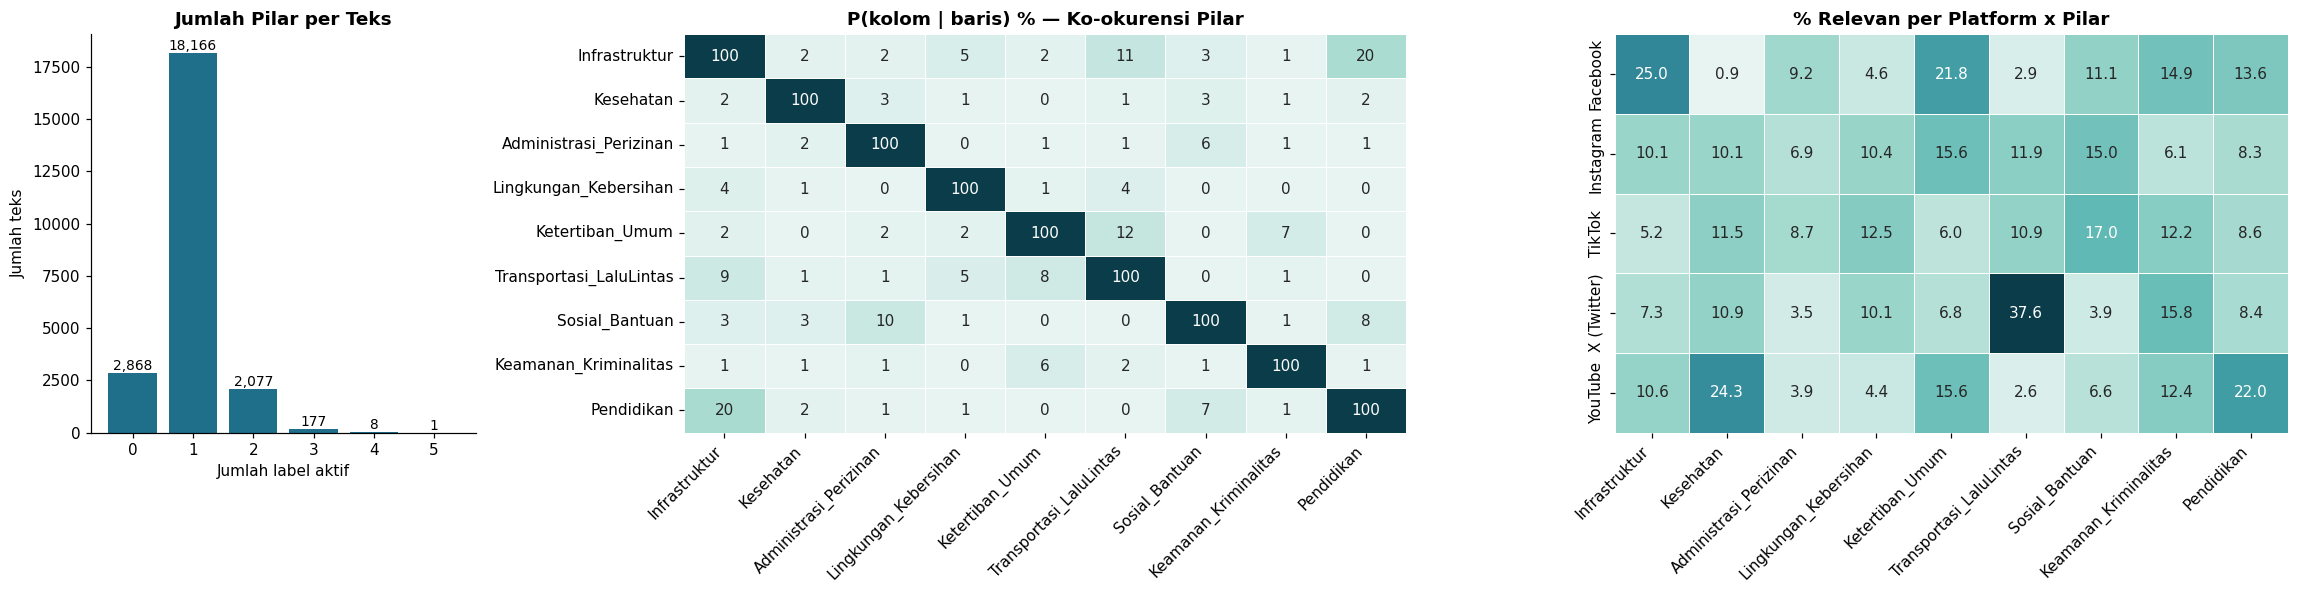

In [27]:
# ===== EDA 12b | Kardinalitas label, ko-okurensi pilar, platform x pilar =====
card = eda[PILAR].sum(axis=1).value_counts().sort_index()
co = pd.DataFrame({b: {a: eda.loc[eda[a] == 1, b].mean() * 100 for a in PILAR} for b in PILAR}).T   # baris = diketahui pilar A
pp = pd.DataFrame({p: eda.loc[eda[PLAT_COL].astype(str) == p, PILAR].mean() * 100 for p in PLATFORMS}).T

fig, ax = plt.subplots(1, 3, figsize=(21, 5.5), gridspec_kw={'width_ratios': [0.8, 1.5, 1.4]})
ax[0].bar(card.index.astype(str), card.values, color=PAL['main'])
for i, v in enumerate(card.values): ax[0].text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
ax[0].set_title('Jumlah Pilar per Teks'); ax[0].set_xlabel('Jumlah label aktif'); ax[0].set_ylabel('Jumlah teks')
sns.heatmap(co, annot=True, fmt='.0f', cmap=CMAP, cbar=False, linewidths=.5, linecolor='white', ax=ax[1])
ax[1].set_title('P(kolom | baris) % — Ko-okurensi Pilar'); plt.setp(ax[1].get_xticklabels(), rotation=45, ha='right')
sns.heatmap(pp, annot=True, fmt='.1f', cmap=CMAP, cbar=False, linewidths=.5, linecolor='white', ax=ax[2])
ax[2].set_title('% Relevan per Platform x Pilar'); plt.setp(ax[2].get_xticklabels(), rotation=45, ha='right')
plt.tight_layout(); plt.show()

## 2.20 Panjang Teks dan Struktur Caption

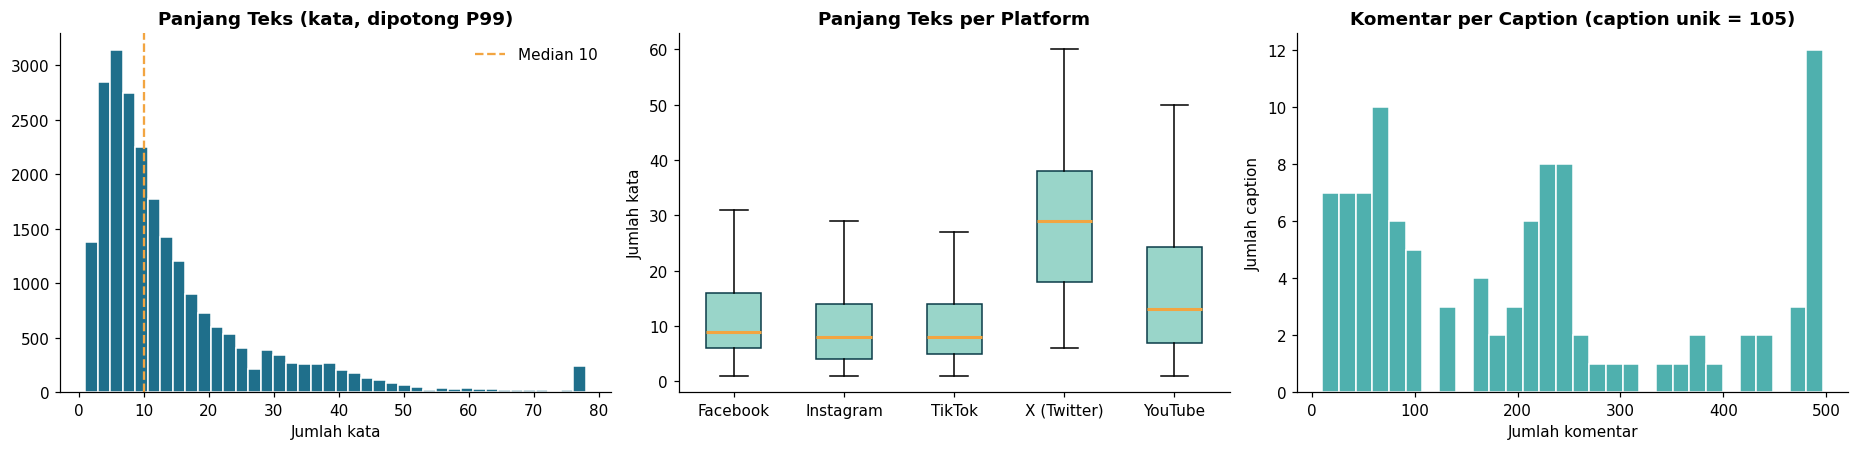

                       count  mean   std  min  25%   50%   75%    max
Panjang teks (kata)  23297.0  14.9  18.5  1.0  5.0  10.0  18.0  745.0


In [28]:
# ===== EDA 12c | Panjang teks & struktur caption =====
eda['n_words'] = eda[TEXT_COL].str.split().str.len()
cap_cnt = eda.groupby(CAP_COL).size()
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].hist(eda['n_words'].clip(upper=eda['n_words'].quantile(.99)), bins=40, color=PAL['main'], edgecolor='white')
ax[0].axvline(eda['n_words'].median(), color=PAL['accent'], ls='--', label=f"Median {eda['n_words'].median():.0f}")
ax[0].set_title('Panjang Teks (kata, dipotong P99)'); ax[0].set_xlabel('Jumlah kata'); ax[0].legend(frameon=False)
bp = ax[1].boxplot([eda.loc[eda[PLAT_COL].astype(str) == p, 'n_words'] for p in PLATFORMS], showfliers=False, patch_artist=True,
                   medianprops={'color': PAL['accent'], 'lw': 2})
ax[1].set_xticklabels(PLATFORMS)
for b in bp['boxes']: b.set_facecolor(PAL['light']); b.set_edgecolor(PAL['dark'])
ax[1].set_title('Panjang Teks per Platform'); ax[1].set_ylabel('Jumlah kata')
ax[2].hist(cap_cnt.clip(upper=cap_cnt.quantile(.99)), bins=30, color=PAL['mid'], edgecolor='white')
ax[2].set_title(f'Komentar per Caption (caption unik = {len(cap_cnt):,})'); ax[2].set_xlabel('Jumlah komentar'); ax[2].set_ylabel('Jumlah caption')
plt.tight_layout(); plt.show()
print(eda['n_words'].describe().round(1).to_frame('Panjang teks (kata)').T)

## 2.21 Pergeseran Train vs Test

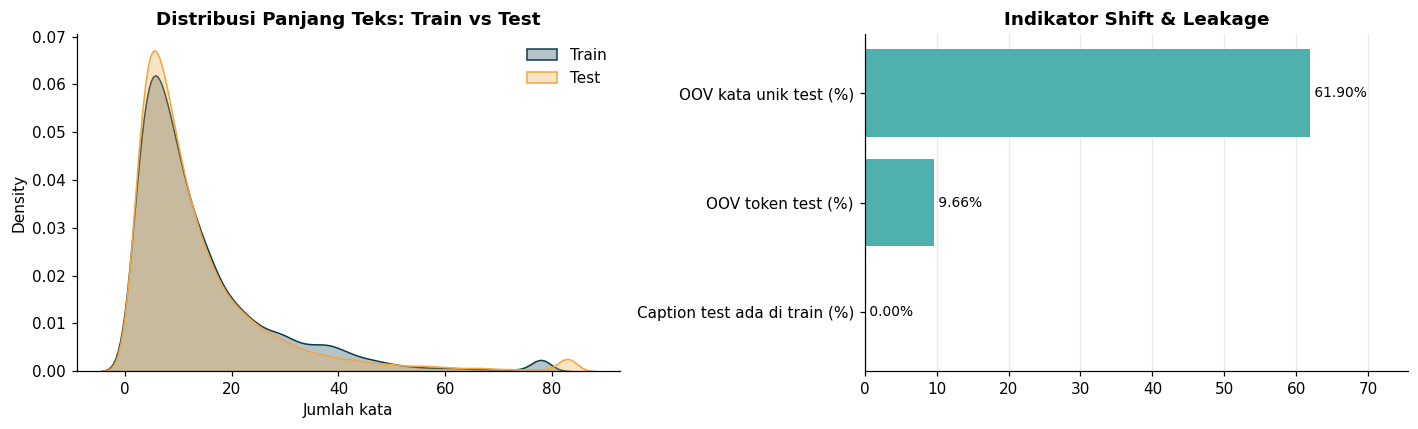

In [32]:
# ===== EDA 12d | Pergeseran distribusi Train vs Test =====
te_tok = test_df[TEXT_COL].fillna('').map(raw_tokens)
te_freq = Counter(itertools.chain.from_iterable(te_tok))
oof_type = np.mean([w not in ALL_FREQ for w in te_freq]) * 100
oof_tok = sum(c for w, c in te_freq.items() if w not in ALL_FREQ) / max(sum(te_freq.values()), 1) * 100
cap_overlap = test_df[CAP_COL].astype(str).str.strip().str.lower().isin(set(train_df[CAP_COL].astype(str).str.strip().str.lower())).mean() * 100
len_te = test_df[TEXT_COL].fillna('').astype(str).str.split().str.len()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for s, lab, col in [(eda['n_words'], 'Train', PAL['dark']), (len_te, 'Test', PAL['accent'])]:
    sns.kdeplot(s.clip(upper=s.quantile(.99)), ax=ax[0], label=lab, color=col, fill=True, alpha=.3)
ax[0].set_title('Distribusi Panjang Teks: Train vs Test'); ax[0].set_xlabel('Jumlah kata'); ax[0].legend(frameon=False)
barh(ax[1], pd.Series({'OOV token test (%)': oof_tok, 'OOV kata unik test (%)': oof_type, 'Caption test ada di train (%)': cap_overlap}),
     'Indikator Shift & Leakage', fmt='{:.2f}%', color=PAL['mid'])
plt.tight_layout(); plt.show()

## 2.22 Top bigram & kata pembeda tiap pilar

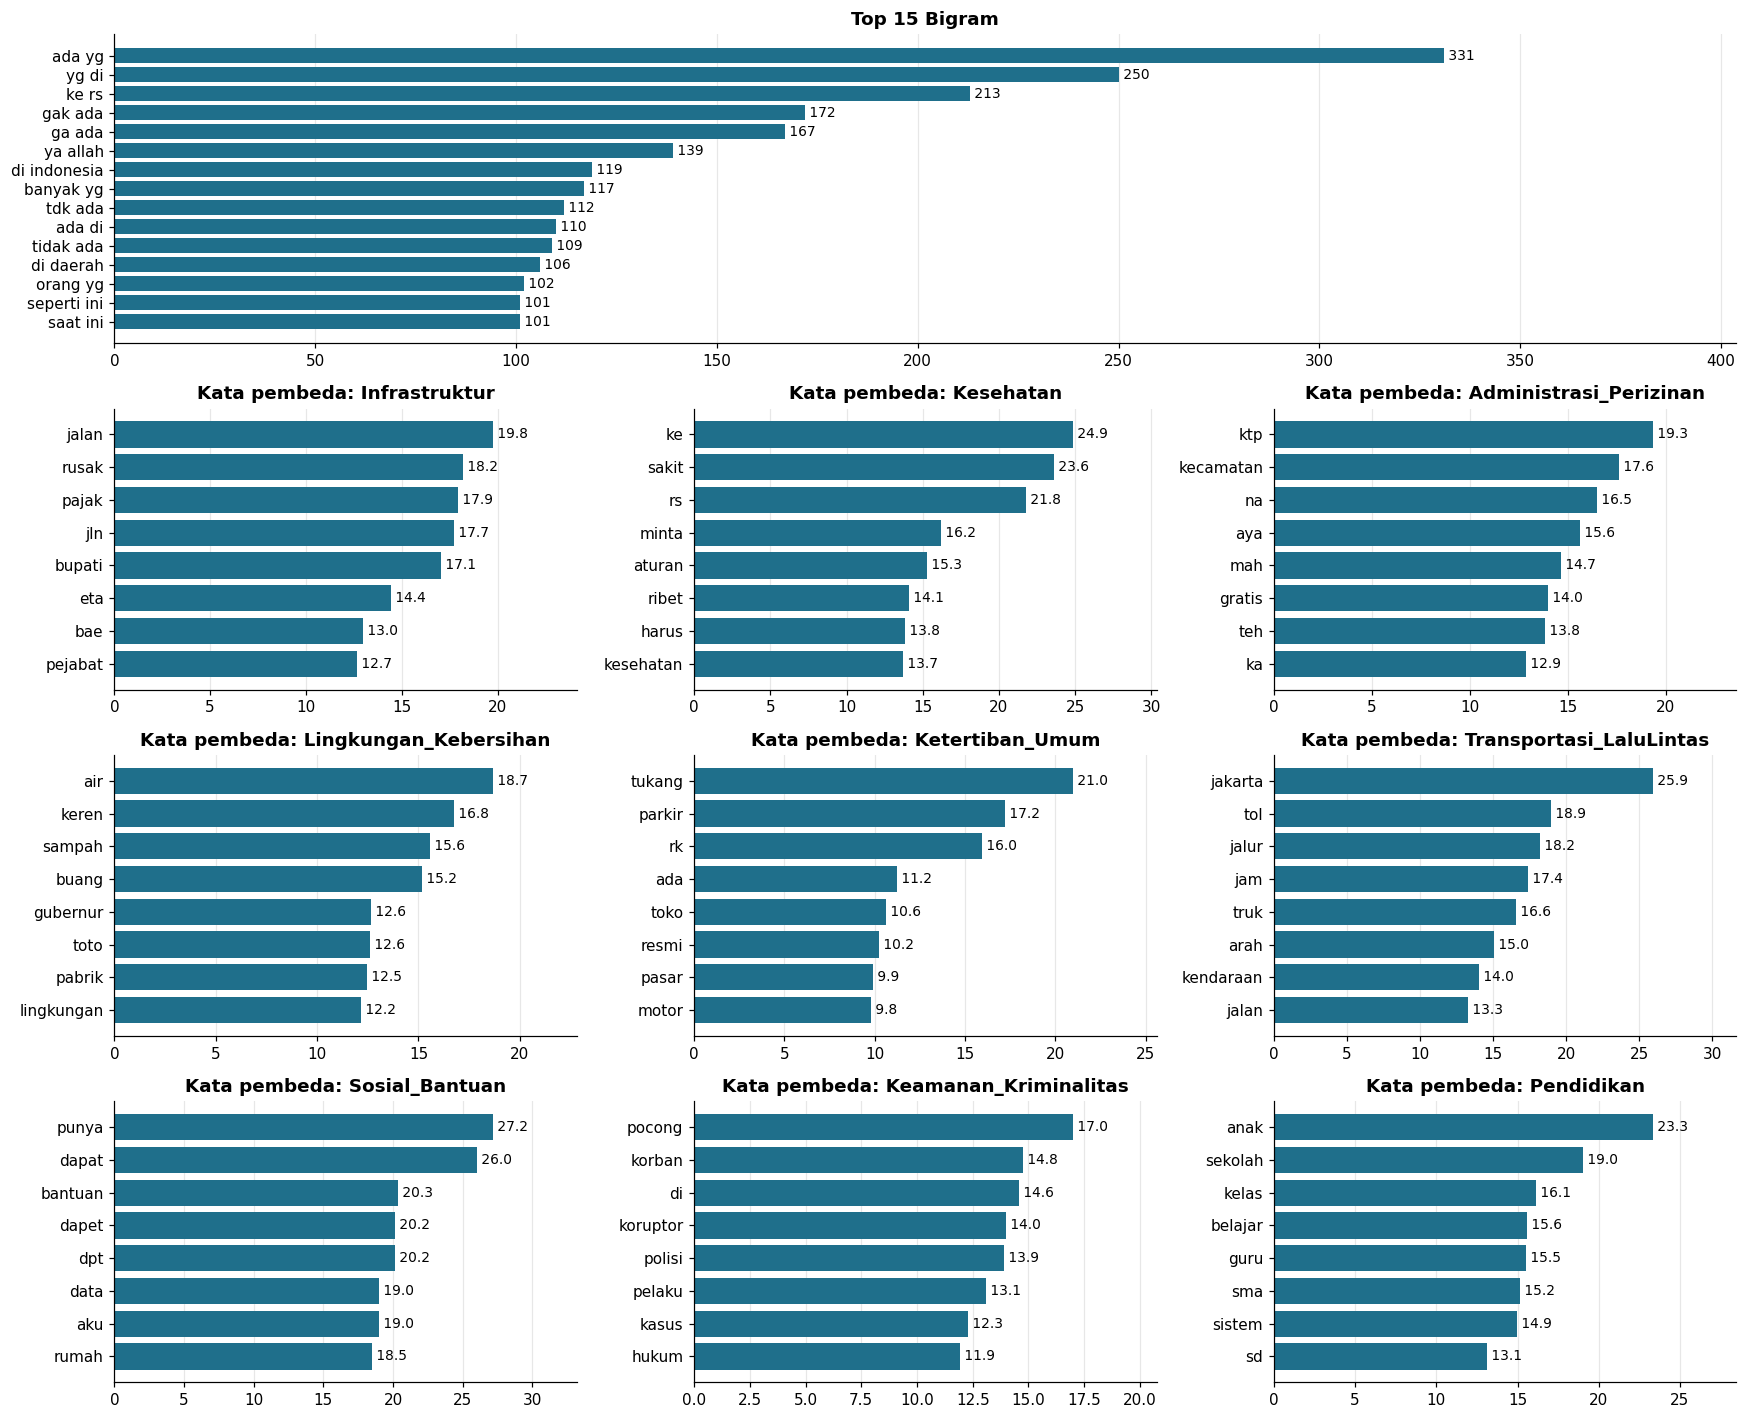

In [30]:
# ===== EDA 12e | Top bigram & kata pembeda tiap pilar (weighted log-odds) =====
big = Counter(itertools.chain.from_iterable(zip(t, t[1:]) for t in eda['tokens']))
top_big = pd.Series({' '.join(k): v for k, v in big.most_common(15)})

# 1. Matriks frekuensi kata x pilar
vocab = [w for w, c in ALL_FREQ.items() if c >= 5]
cnt = pd.DataFrame({c: group_counter(eda[c] == 1) for c in PILAR}, index=vocab).fillna(0)
tot = pd.Series(ALL_FREQ)[vocab]

# 2. Weighted log-odds (prior informatif Dirichlet) grup vs sisanya
def log_odds(col, a0=500):
    y1, y2 = cnt[col], tot - cnt[col]
    n1, n2 = y1.sum(), y2.sum(); a = a0 * tot / tot.sum()
    d = np.log((y1 + a) / (n1 + a0 - y1 - a)) - np.log((y2 + a) / (n2 + a0 - y2 - a))
    return d / np.sqrt(1 / (y1 + a) + 1 / (y2 + a))

fig = plt.figure(figsize=(16, 13)); gs = fig.add_gridspec(4, 3, height_ratios=[1.1, 1, 1, 1])
ax0 = fig.add_subplot(gs[0, :]); barh(ax0, top_big, 'Top 15 Bigram')
for i, c in enumerate(PILAR):
    ax = fig.add_subplot(gs[1 + i // 3, i % 3])
    z = log_odds(c).sort_values(ascending=False).head(8)
    barh(ax, z, f'Kata pembeda: {c}', fmt='{:.1f}', color=PAL['main'])
plt.tight_layout(); plt.show()

# 3. Pra-Pemrosesan
## 3.1 Import n Config


In [1]:
import os, gc, copy, math, json, random, re, time, unicodedata, warnings
from collections import Counter, defaultdict
import numpy as np, pandas as pd

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast, GradScaler
from transformers import (
    AutoTokenizer, AutoModel, AutoConfig,
    get_cosine_schedule_with_warmup
)
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedGroupKFold
import optuna

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

KeyboardInterrupt: 

In [ ]:
class CFG:
    seed            = 42
    n_folds         = 5
    epochs          = 5          # Paper: 3-6 cukup; early stop via patience
    batch_size      = 16
    lr              = 2e-5
    weight_decay    = 0.01
    warmup_ratio    = 0.06
    max_grad_norm   = 1.0
    fp16            = True
    patience        = 3          # Early stopping

    # Backbone A: IndoBERTweet (Koto et al., 2021)
    model_a_name    = "indolem/indobertweet-base-uncased"
    max_len_a       = 128
    weight_a        = 0.55

    # Backbone B: IndoBERT-p2
    model_b_name    = "indobenchmark/indobert-base-p2"
    max_len_b       = 192
    weight_b        = 0.45

    # Token budget: [CLS] cap [SEP] com [SEP] = 3 special
    max_caption_tokens = 40     # EDA: caption pendek; sisakan ruang utk komentar

    output_dir      = OUTPUT_DIR
    os.makedirs(output_dir, exist_ok=True)

def seed_everything(seed=42):
    random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(CFG.seed)

## 3.2 Slang Normalization

In [ ]:
# ===== Pra-pemrosesan: gunakan artefak EDA sebagai single source of truth =====

# 1. Pastikan kamus slang dari EDA sudah ada
if 'SLANG_DICT' not in globals():
    raise NameError("SLANG_DICT belum tersedia. Jalankan sel EDA yang mendefinisikan SLANG_DICT terlebih dahulu.")

# 2. Perluas SLANG_DICT dari leksikon eksternal jika tersedia
_slang_full = {}

if 'find_lexicon' in globals() and 'read_pairs' in globals():
    for lex in ('salsabila', 'ibrohim'):
        path = find_lexicon(lex)
        if path:
            pairs = read_pairs(path)
            if pairs:
                _slang_full.update({
                    str(k).lower(): str(v).lower()
                    for k, v in pairs
                })

# 3. Kamus kurasi EDA menjadi prioritas akhir
_slang_full.update({
    str(k).lower(): str(v).lower()
    for k, v in SLANG_DICT.items()
})

SLANG_DICT = _slang_full

## 3.3 Emoji Normalization

In [ ]:
# ===== Emoji: tangani seluruh emoji, jangan hardcode parsial =====

def _emoji_name(emo: str) -> str:
    try:
        name = emoji.demojize(emo, language='id')
    except Exception:
        name = emoji.demojize(emo)
    return name.strip(':').replace('_', ' ').strip()

# 4. Bangun fallback emoji dari seluruh emoji yang dikenal library
_emoji_source = getattr(emoji, 'EMOJI_DATA', None) or getattr(emoji, 'UNICODE_EMOJI', {})

_emoji_full = {}
for emo in _emoji_source:
    name = _emoji_name(emo)
    if name and name != emo:
        _emoji_full[emo] = f" {name} "

# 5. Jika EDA punya EMOJI_FALLBACK kurasi, gunakan sebagai override
if 'EMOJI_FALLBACK' in globals():
    _emoji_full.update({
        str(k): f" {str(v).strip()} "
        for k, v in EMOJI_FALLBACK.items()
    })

EMOJI_FALLBACK = _emoji_full

## 3.4 Audit Slang, Emoji, n Gibberish

In [ ]:
# Audit cakupan kamus dan emoji
print(f"SLANG_DICT entries: {len(SLANG_DICT):,}")
print(f"EMOJI_FALLBACK entries: {len(EMOJI_FALLBACK):,}")

In [ ]:
import re

GIBBERISH_WHITELIST = set()

if 'ACRONYM_OK' in globals():
    GIBBERISH_WHITELIST.update(str(w).lower() for w in ACRONYM_OK)

if 'SLANG_DICT' in globals():
    GIBBERISH_WHITELIST.update(str(k).lower() for k in SLANG_DICT.keys())
    GIBBERISH_WHITELIST.update(str(v).lower() for v in SLANG_DICT.values())

GIBBERISH_WHITELIST.update({
    'bpjs', 'ktp', 'kk', 'rt', 'rw', 'stnk', 'sim', 'dpr', 'mpr',
    'pns', 'pln', 'pdam', 'kai', 'mrt', 'lrt', 'cctv', 'apk',
    'sma', 'smk', 'smp', 'sd', 'tk', 'puskesmas', 'posyandu',
    'dtk', 'fyp', 'dm', 'wa', 'ig', 'fb', 'pbb', 'bumn', 'bumd'
})

VOW = set('aiueo')
CONS_RUN = re.compile(r'[^aiueo\s]{5,}')
VOW_RUN = re.compile(r'[aiueo]{6,}')

def is_gibberish_token(tok: str) -> bool:
    tok = tok.lower()

    if len(tok) < 5:
        return False

    if tok in GIBBERISH_WHITELIST:
        return False

    if not tok.isalpha():
        return True

    if not VOW.intersection(tok):
        return True

    v_ratio = sum(ch in VOW for ch in tok) / len(tok)
    if v_ratio <= 0.15 or v_ratio >= 0.85:
        return True

    if len(set(tok)) <= 2 and len(tok) >= 6:
        return True

    if CONS_RUN.search(tok):
        return True

    if VOW_RUN.search(tok):
        return True

    return False

def remove_gibberish(text: str) -> str:
    return ' '.join(tok for tok in text.split() if not is_gibberish_token(tok))

## 3.5 Text Cleaning 

In [ ]:
if 'clean_text_v8' not in globals():
    raise NameError('clean_text_v8 belum tersedia.')

def sanitize_text(text: str) -> str:
    if not isinstance(text, str) or not text.strip():
        return ''

    text = clean_text_v8(text).lower()
    text = remove_gibberish(text)
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [ ]:
# Terapkan ke train dan test
train_df['Judul_Clean'] = train_df['Judul_Caption'].fillna('').apply(sanitize_text)
train_df['Teks_Clean']  = train_df['Teks'].fillna('').apply(sanitize_text)

test_df['Judul_Clean']  = test_df['Judul_Caption'].fillna('').apply(sanitize_text)
test_df['Teks_Clean']   = test_df['Teks'].fillna('').apply(sanitize_text)

print("Sanitasi final selesai.")

## 3.6 Zero-Leakage StratifiedGroupKFold

In [33]:
# Grup berdasarkan ID Judul_Caption (mencegah 105 berita train bocor ke validation)
train_df['caption_group'] = train_df['Judul_Caption'].astype(str).str.strip().str.lower().factorize()[0]

# Proxy stratifikasi pilar paling langka + platform
def get_strat_key(row):
    active_rare = []
    if row['Administrasi_Perizinan']:
        active_rare.append('ADM')
    if row['Lingkungan_Kebersihan']:
        active_rare.append('LNG')
    if row['Transportasi_LaluLintas']:
        active_rare.append('TRN')
    tag = "_".join(active_rare) if active_rare else "OTHER"
    return f"{row['Source']}_{tag}"

train_df['strat_key'] = train_df.apply(get_strat_key, axis=1)

sgkf = StratifiedGroupKFold(n_splits=CFG.n_folds, shuffle=True, random_state=CFG.seed)
train_df['fold'] = -1
for fold_idx, (tr_idx, val_idx) in enumerate(sgkf.split(train_df, train_df['strat_key'], groups=train_df['caption_group'])):
    train_df.loc[val_idx, 'fold'] = fold_idx

print("Distribusi Sampel per Fold (Zero-Leakage):")
for f in range(CFG.n_folds):
    sub = train_df[train_df['fold'] == f]
    print(f"  Fold {f}: {len(sub):5d} baris | {sub['caption_group'].nunique():2d} grup caption unik")



Distribusi Sampel per Fold (Zero-Leakage):
  Fold 0:  3499 baris | 18 grup caption unik
  Fold 1:  5499 baris | 21 grup caption unik
  Fold 2:  4354 baris | 20 grup caption unik
  Fold 3:  5259 baris | 24 grup caption unik
  Fold 4:  4686 baris | 23 grup caption unik


# 4. Modeling
## 4.1 Token Budget & Segment-Aware Dataset

In [6]:
class SegmentAwareDataset(Dataset):
    def __init__(self, df, tokenizer, max_len=128, max_caption_tokens=40, is_train=True):
        self.df       = df
        self.tok      = tokenizer
        self.max_len  = max_len
        self.max_cap  = max_caption_tokens
        self.is_train = is_train
        self.captions = df['Judul_Clean'].values
        self.comments = df['Teks_Clean'].values
        self.sources  = df['Source'].astype(str).values
        if is_train:
            self.labels = df[target_cols].values.astype(np.float32)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # Format: [CLS] [PLATFORM] caption [SEP] comment [SEP]
        cap_text = f"[{self.sources[idx].upper()}] {self.captions[idx]}"
        com_text = str(self.comments[idx])

        cap_ids = self.tok(cap_text, add_special_tokens=False)['input_ids'][:self.max_cap]
        avail   = self.max_len - 3 - len(cap_ids)          # −3 utk [CLS],[SEP],[SEP]
        com_ids = self.tok(com_text, add_special_tokens=False)['input_ids'][:max(avail, 0)]

        input_ids      = [self.tok.cls_token_id] + cap_ids + [self.tok.sep_token_id] + com_ids + [self.tok.sep_token_id]
        token_type_ids = [0] * (len(cap_ids) + 2) + [1] * (len(com_ids) + 1)
        attention_mask = [1] * len(input_ids)

        item = {
            'input_ids':      input_ids,
            'token_type_ids': token_type_ids,
            'attention_mask': attention_mask,
        }
        if self.is_train:
            item['labels'] = torch.tensor(self.labels[idx], dtype=torch.float32)
        return item


def dynamic_collate(batch, pad_id=0):
    max_l = max(len(x['input_ids']) for x in batch)
    out = {'input_ids': [], 'token_type_ids': [], 'attention_mask': []}
    labels = []
    for x in batch:
        pad = max_l - len(x['input_ids'])
        out['input_ids'].append(x['input_ids'] + [pad_id] * pad)
        out['token_type_ids'].append(x['token_type_ids'] + [0] * pad)
        out['attention_mask'].append(x['attention_mask'] + [0] * pad)
        if 'labels' in x: labels.append(x['labels'])
    out = {k: torch.tensor(v, dtype=torch.long) for k, v in out.items()}
    if labels: out['labels'] = torch.stack(labels)
    return out

SegmentAwareDataset & dynamic_collate_fn siap!


## 4.2 Model Architecture with Comment-Segment Head


In [7]:
class CommentSegmentHead(nn.Module):
    def __init__(self, hidden_dim=768, num_labels=9, dropouts=(0.2, 0.3, 0.4, 0.5)):
        super().__init__()
        self.dropouts = nn.ModuleList([nn.Dropout(p) for p in dropouts])
        self.classifier = nn.Linear(hidden_dim * 2, num_labels)

    def forward(self, seq_out, attn_mask, token_type_ids=None):
        # cls representation
        cls_rep = seq_out[:, 0, :]
    
        # fallback jika token_type_ids tidak diberikan
        if token_type_ids is None:
            token_type_ids = torch.zeros_like(attn_mask, dtype=torch.long)
    
        # mask segmen komentar
        com_mask = ((token_type_ids == 1).float() * attn_mask.float())
    
        # fallback per baris jika tidak ada token komentar
        has_com = com_mask.sum(dim=1, keepdim=True) > 0
        com_mask = torch.where(has_com, com_mask, attn_mask.float())
    
        # masked mean segmen komentar
        num = (seq_out * com_mask.unsqueeze(-1)).sum(dim=1)
        den = com_mask.sum(dim=1, keepdim=True).clamp(min=1e-9)
        mean_com = num / den
    
        # gabungkan cls dan comment mean
        fused = torch.cat([cls_rep, mean_com], dim=-1)
    
        # multi-sample dropout hanya saat training
        if self.training:
            logits = torch.stack([
                self.classifier(dp(fused)) for dp in self.dropouts
            ]).mean(0)
        else:
            logits = self.classifier(fused)
    
        return logits


class ACTIONModel(nn.Module):
    def __init__(self, model_name, num_labels=9):
        super().__init__()
        cfg = AutoConfig.from_pretrained(model_name)
        cfg.update({"output_hidden_states": False})
        self.encoder = AutoModel.from_pretrained(model_name, config=cfg)
        self.head    = CommentSegmentHead(cfg.hidden_size, num_labels)

    def forward(self, input_ids, attention_mask, token_type_ids=None):
        out = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
        )
        return self.head(out.last_hidden_state, attention_mask, token_type_ids)

ACTIONModelV8 terdefinisi.


## 4.3 Adaptive Loss Function & Smoothed Thresholding


In [8]:
pos_counts  = train_df[target_cols].sum().values
neg_counts  = len(train_df) - pos_counts
pos_weights = np.sqrt(neg_counts / pos_counts)
pos_weight_tensor = torch.tensor(pos_weights, dtype=torch.float32).to(device)

def get_loss_fn(use_focal=False, gamma=2.0):
    if use_focal:
        class FocalBCE(nn.Module):
            def __init__(self, gamma, pw):
                super().__init__()
                self.gamma = gamma
                self.pw = pw
            def forward(self, logits, targets):
                bce = F.binary_cross_entropy_with_logits(
                    logits, targets, pos_weight=self.pw, reduction='none'
                )
                p = torch.sigmoid(logits)
                pt = targets * p + (1 - targets) * (1 - p)
                focal_w = (1 - pt) ** self.gamma
                return (focal_w * bce).mean()
        return FocalBCE(gamma, pos_weight_tensor)
    return nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)

Pos Weights Tensor: [2.7  2.84 3.6  3.27 2.51 3.08 2.66 2.75 2.69]


## 4.4 Hyperparameter Tuning dengan Optuna

In [ ]:
def objective(trial):
    # --- Search space (paper-backed ranges) ---
    lr           = trial.suggest_float("lr", 5e-6, 5e-5, log=True)
    batch_size   = trial.suggest_categorical("batch_size", [8, 16, 32])
    weight_decay = trial.suggest_float("weight_decay", 0.005, 0.05, log=True)
    warmup_ratio = trial.suggest_float("warmup_ratio", 0.03, 0.15)
    dropout_idx  = trial.suggest_categorical("dropout_set", [0, 1, 2])
    use_focal    = trial.suggest_categorical("use_focal", [False, True])
    gamma        = trial.suggest_float("gamma", 1.0, 3.0) if use_focal else 2.0

    dropout_sets = [
        (0.1, 0.2, 0.3),
        (0.2, 0.3, 0.4),
        (0.3, 0.4, 0.5),
    ]

    # --- Validasi cepat: 1 fold, max 2 epoch ---
    va_sub = train_df[train_df['fold'] == 0].reset_index(drop=True)
    tr_sub = train_df[train_df['fold'] != 0]

    if len(tr_sub) > 5000:
        tr_sub = tr_sub.sample(n=5000, random_state=CFG.seed)
    
    tr_sub = tr_sub.reset_index(drop=True)

    tokenizer = AutoTokenizer.from_pretrained(CFG.model_a_name)
    collate   = lambda b: dynamic_collate(b, tokenizer.pad_token_id)

    tr_ds = SegmentAwareDataset(tr_sub, tokenizer, CFG.max_len_a, CFG.max_caption_tokens, True)
    va_ds = SegmentAwareDataset(va_sub, tokenizer, CFG.max_len_a, CFG.max_caption_tokens, True)
    tr_dl = DataLoader(tr_ds, batch_size=batch_size, shuffle=True, collate_fn=collate, drop_last=True)
    va_dl = DataLoader(va_ds, batch_size=batch_size*2, shuffle=False, collate_fn=collate)

    model = ACTIONModel(CFG.model_a_name).to(device)
    model.head.dropouts = nn.ModuleList([nn.Dropout(p) for p in dropout_sets[dropout_idx]])

    loss_fn   = get_loss_fn(use_focal, gamma)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    total_steps = len(tr_dl) * 2
    scheduler   = get_cosine_schedule_with_warmup(
        optimizer, int(total_steps * warmup_ratio), total_steps
    )
    scaler = GradScaler(enabled=CFG.fp16)

    best_f1 = 0.0
    for epoch in range(2):
        model.train()
        for batch in tr_dl:
            optimizer.zero_grad()
            with autocast(enabled=CFG.fp16):
                logits = model(
                    batch['input_ids'].to(device),
                    batch['attention_mask'].to(device),
                    batch['token_type_ids'].to(device),
                )
                loss = loss_fn(logits, batch['labels'].to(device))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.max_grad_norm)
            scaler.step(optimizer); scaler.update(); scheduler.step()

        # Evaluasi
        model.eval(); preds, trues = [], []
        with torch.no_grad():
            for batch in va_dl:
                with autocast(enabled=CFG.fp16):
                    logits = model(
                        batch['input_ids'].to(device),
                        batch['attention_mask'].to(device),
                        batch['token_type_ids'].to(device),
                    )
                preds.append(torch.sigmoid(logits).cpu().numpy())
                trues.append(batch['labels'].numpy())

        preds = np.vstack(preds); trues = np.vstack(trues)
        f1 = np.mean([
            f1_score(trues[:, i], (preds[:, i] >= 0.5).astype(int), zero_division=0)
            for i in range(len(target_cols))
        ])
        best_f1 = max(best_f1, f1)
        trial.report(best_f1, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

    del model; torch.cuda.empty_cache(); gc.collect()
    return best_f1

In [ ]:
# Jalankan Optuna + Hyperband
study = optuna.create_study(
    direction="maximize",
    pruner=optuna.pruners.HyperbandPruner(min_resource=1, max_resource=3, reduction_factor=3),
    sampler=optuna.samplers.TPESampler(seed=CFG.seed),
)
study.optimize(objective, n_trials=20, show_progress_bar=False)

print(f"Best trial: {study.best_trial.value:.5f}")
print(f"Best params: {json.dumps(study.best_trial.params, indent=2)}")

# Simpan ke CFG
bp = study.best_trial.params
CFG.lr           = bp['lr']
CFG.batch_size   = bp['batch_size']
CFG.weight_decay = bp['weight_decay']
CFG.warmup_ratio = bp['warmup_ratio']
CFG.use_focal    = bp['use_focal']
CFG.gamma        = bp.get('gamma', 2.0)
CFG.dropout_set  = [(0.1,0.2,0.3), (0.2,0.3,0.4), (0.3,0.4,0.5)][bp['dropout_set']]

# 5. Training
## 5.1 Fungsi Training

In [9]:
def train_single_model(model_name, max_len, train_df, test_df, model_tag="Model"):
    print(f"{'='*30} {model_tag}: {model_name} (max_len={max_len}) {'='*30}")
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    collate   = lambda b: dynamic_collate(b, tokenizer.pad_token_id)

    test_ds = SegmentAwareDataset(test_df, tokenizer, max_len, CFG.max_caption_tokens, False)
    test_dl = DataLoader(test_ds, batch_size=CFG.batch_size*2, shuffle=False, collate_fn=collate)

    oof_logits   = np.zeros((len(train_df), len(target_cols)), dtype=np.float32)
    test_logits  = np.zeros((len(test_df), len(target_cols)), dtype=np.float32)
    loss_fn      = get_loss_fn(CFG.use_focal, CFG.gamma)

    for fold in range(CFG.n_folds):
        print(f"  Fold {fold+1}/{CFG.n_folds}")
        tr_sub = train_df[train_df['fold'] != fold].reset_index(drop=True)
        va_sub = train_df[train_df['fold'] == fold].reset_index(drop=True)
        va_idx = train_df[train_df['fold'] == fold].index.values

        tr_dl = DataLoader(
            SegmentAwareDataset(tr_sub, tokenizer, max_len, CFG.max_caption_tokens, True),
            batch_size=CFG.batch_size, shuffle=True, collate_fn=collate, drop_last=True,
        )
        va_dl = DataLoader(
            SegmentAwareDataset(va_sub, tokenizer, max_len, CFG.max_caption_tokens, True),
            batch_size=CFG.batch_size*2, shuffle=False, collate_fn=collate,
        )

        model = ACTIONModel(model_name).to(device)
        model.head.dropouts = nn.ModuleList([nn.Dropout(p) for p in CFG.dropout_set])

        optimizer = torch.optim.AdamW(
            model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay
        )
        total_steps = len(tr_dl) * CFG.epochs
        scheduler   = get_cosine_schedule_with_warmup(
            optimizer, int(total_steps * CFG.warmup_ratio), total_steps
        )
        scaler = GradScaler(enabled=CFG.fp16)

        best_val_loss = float('inf')
        patience_cnt  = 0
        best_state    = None

        for epoch in range(CFG.epochs):
            # --- Train ---
            model.train(); tr_loss = 0.0
            for batch in tr_dl:
                optimizer.zero_grad()
                with autocast(enabled=CFG.fp16):
                    logits = model(
                        batch['input_ids'].to(device),
                        batch['attention_mask'].to(device),
                        batch['token_type_ids'].to(device),
                    )
                    loss = loss_fn(logits, batch['labels'].to(device))
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.max_grad_norm)
                scaler.step(optimizer); scaler.update(); scheduler.step()
                tr_loss += loss.item()

            # --- Validate ---
            model.eval(); va_loss = 0.0; val_preds = []
            with torch.no_grad():
                for batch in va_dl:
                    with autocast(enabled=CFG.fp16):
                        logits = model(
                            batch['input_ids'].to(device),
                            batch['attention_mask'].to(device),
                            batch['token_type_ids'].to(device),
                        )
                        loss = loss_fn(logits, batch['labels'].to(device))
                    va_loss += loss.item()
                    val_preds.append(logits.cpu().numpy())

            tr_loss /= len(tr_dl); va_loss /= len(va_dl)
            print(f"    Epoch {epoch+1}/{CFG.epochs}  tr_loss={tr_loss:.4f}  va_loss={va_loss:.4f}")

            # --- Early stopping (paper 3911: berhenti saat val loss stagnan) ---
            if va_loss < best_val_loss:
                best_val_loss = va_loss
                patience_cnt  = 0
                best_state    = copy.deepcopy(model.state_dict())
                oof_logits[va_idx] = np.vstack(val_preds)
            else:
                patience_cnt += 1
                if patience_cnt >= CFG.patience:
                    print(f"    Early stop di epoch {epoch+1}")
                    break

        # Load best & predict test
        model.load_state_dict(best_state)
        model.eval(); fold_test = []
        with torch.no_grad():
            for batch in test_dl:
                with autocast(enabled=CFG.fp16):
                    logits = model(
                        batch['input_ids'].to(device),
                        batch['attention_mask'].to(device),
                        batch['token_type_ids'].to(device),
                    )
                fold_test.append(logits.cpu().numpy())
        test_logits += np.vstack(fold_test) / CFG.n_folds

        del model, optimizer, scheduler, best_state
        torch.cuda.empty_cache(); gc.collect()

    return oof_logits, test_logits

## 5.2 Jalankan Backbone

In [ ]:
oof_A, test_A = train_single_model(CFG.model_a_name, CFG.max_len_a, train_df, test_df, "IndoBERTweet")
np.save(os.path.join(CFG.output_dir, "oof_logits_A.npy"), oof_A)
np.save(os.path.join(CFG.output_dir, "test_logits_A.npy"), test_A)
print("Backbone A selesai!")

In [ ]:
oof_B, test_B = train_single_model(CFG.model_b_name, CFG.max_len_b, train_df, test_df, "IndoBERT_p2")
np.save(os.path.join(CFG.output_dir, "oof_logits_B.npy"), oof_B)
np.save(os.path.join(CFG.output_dir, "test_logits_B.npy"), test_B)
print("Backbone B selesai!")

## 5.3 Probability Blending & Threshold Calibration


In [ ]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -15, 15)))

# Blend
probs_A = sigmoid(oof_A); probs_B = sigmoid(oof_B)
oof_blend = CFG.weight_a * probs_A + CFG.weight_b * probs_B

test_probs_A = sigmoid(test_A); test_probs_B = sigmoid(test_B)
test_blend   = CFG.weight_a * test_probs_A + CFG.weight_b * test_probs_B

y_true = train_df[target_cols].values

In [ ]:
def optimize_thresholds(probs, truths, shrink=0.30):
    grid = np.arange(0.30, 0.70, 0.01)
    best_ts = []
    for i in range(probs.shape[1]):
        scores = []
        for t in grid:
            pred = (probs[:, i] >= t).astype(int)
            scores.append(f1_score(truths[:, i], pred, zero_division=0))
        smoothed = np.convolve(scores, np.ones(5)/5, mode='same')
        best_t   = grid[np.argmax(smoothed)]
        shrunk_t = shrink * 0.50 + (1.0 - shrink) * best_t
        best_ts.append(shrunk_t)
    return np.array(best_ts)

best_thresholds = optimize_thresholds(oof_blend, y_true)

In [ ]:
# Evaluasi OOF
f1s = []
for i, c in enumerate(target_cols):
    pred = (oof_blend[:, i] >= best_thresholds[i]).astype(int)
    f1   = f1_score(y_true[:, i], pred, zero_division=0)
    f1s.append(f1)
    print(f"  {c:<28} thr={best_thresholds[i]:.3f}  F1={f1:.5f}")

print(f"\n  OOF Mean Column-wise Macro F1: {np.mean(f1s):.5f}")

# 6. Submission Generation & Final Verification


In [ ]:
test_preds = (test_blend >= best_thresholds).astype(int)
sub = pd.DataFrame({'ID': test_df['ID']})
for i, c in enumerate(target_cols):
    sub[c] = test_preds[:, i]

sub_path = os.path.join(CFG.output_dir, 'submission.csv')
sub.to_csv(sub_path, index=False)
print(f"Submission: {sub.shape} | NaN: {sub.isna().sum().sum()} | saved → {sub_path}")
print(sub[target_cols].sum())

In [ ]:
# ===== FINAL SUBMISSION: Pastikan file ada di /kaggle/working/submission.csv =====
import os
import numpy as np
import pandas as pd

# Path wajib Kaggle
KAGGLE_WORKING = '/kaggle/working/'
KAGGLE_SUB_PATH = os.path.join(KAGGLE_WORKING, 'submission.csv')

# Pastikan direktori ada
os.makedirs(KAGGLE_WORKING, exist_ok=True)

# Buat submission dari test_blend dan best_thresholds
test_preds = (test_blend >= best_thresholds).astype(int)

sub = pd.DataFrame({'ID': test_df['ID']})
for i, c in enumerate(target_cols):
    sub[c] = test_preds[:, i]

# Simpan ke path wajib Kaggle
sub.to_csv(KAGGLE_SUB_PATH, index=False)

# Juga simpan ke CFG.output_dir jika berbeda (backup)
if os.path.abspath(CFG.output_dir) != os.path.abspath(KAGGLE_WORKING):
    backup_path = os.path.join(CFG.output_dir, 'submission.csv')
    sub.to_csv(backup_path, index=False)
    print(f"Backup juga disimpan di: {backup_path}")

# ===== VERIFIKASI FINAL =====
assert os.path.exists(KAGGLE_SUB_PATH), f"FATAL: {KAGGLE_SUB_PATH} tidak ditemukan!"

loaded = pd.read_csv(KAGGLE_SUB_PATH)
assert loaded.shape[0] == len(test_df), "Jumlah baris submission tidak sesuai!"
assert loaded.isna().sum().sum() == 0, "Ada nilai NaN di submission!"
assert list(loaded.columns) == ['ID'] + target_cols, "Kolom submission tidak sesuai!"

print("=" * 60)
print("✅ SUBMISSION BERHASIL DISIMPAN")
print("=" * 60)
print(f"Path     : {KAGGLE_SUB_PATH}")
print(f"Shape    : {loaded.shape}")
print(f"NaN      : {loaded.isna().sum().sum()}")
print(f"Kolom    : {list(loaded.columns)}")
print()
print("Distribusi prediksi positif per pilar:")
print(loaded[target_cols].sum())
print()
print("File siap untuk submit ke Kaggle.")